# MiniSepVAE Training Metrics — Interpretation Guide

**What this notebook does:**
Each epoch prints a line like:
```
[ 12/50] loss=1.2341  rec=0.0213  probe_c=0.731  probe_e=0.689  xhead=0.582  G1=✗  G2=✓
```

This notebook builds **scenario illustrations** for each metric and combined scenarios, showing:
- What **bad / uncertain / normal / ideal** looks like
- Corresponding **PCA scatter plots** of the disease heads
- **Gate logic** (G1, G2) and what must be true to move to the next experiment stage

---
## Quick Reference Table

| Metric | Meaning | Target | Bad |
|--------|---------|--------|-----|
| `loss` | Weighted sum of all losses | Decreasing → stable | Increasing or NaN |
| `rec` | Pixel reconstruction error | <0.05 by epoch 10 | >0.15 sustained |
| `probe_c` | Linear AUC: does cardio head encode cardio? | >0.75 (G1) | <0.60 |
| `probe_e` | Linear AUC: does effusion head encode effusion? | >0.75 (G1) | <0.60 |
| `xhead` | Cross-leakage: does each head encode the OTHER disease? | <0.65 (G2) | >0.75 |
| `G1` | ✓ iff probe_c > 0.75 AND probe_e > 0.75 | Must be ✓ by epoch 30 | Both probes low |
| `G2` | ✓ iff xhead < 0.65 | Must be ✓ by epoch 30 | Heads not disentangled |

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
from scipy.stats import multivariate_normal
from sklearn.decomposition import PCA

matplotlib.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

COLORS = {'bad': '#e74c3c', 'uncertain': '#f39c12', 'normal': '#3498db', 'ideal': '#27ae60'}
SCENARIO_NAMES = ['Bad', 'Uncertain', 'Normal', 'Ideal']
EPOCHS = np.arange(1, 51)

def shade_gates(ax, g1_epoch=None, g2_epoch=None):
    """Shade the region after gates are met."""
    if g1_epoch:
        ax.axvline(g1_epoch, color='green', linestyle='--', alpha=0.5, lw=1.5)
        ax.text(g1_epoch+0.5, ax.get_ylim()[1]*0.95, 'G1✓', color='green', fontsize=8)

def add_zone(ax, y_bad, y_uncertain, y_ideal, flip=False):
    """Background shading for target zones."""
    ymin, ymax = ax.get_ylim()
    if not flip:
        ax.axhspan(ymin, y_bad, alpha=0.08, color='red')
        ax.axhspan(y_bad, y_uncertain, alpha=0.06, color='orange')
        ax.axhspan(y_ideal, ymax, alpha=0.08, color='green')
    else:
        ax.axhspan(y_bad, ymax, alpha=0.08, color='red')
        ax.axhspan(y_uncertain, y_bad, alpha=0.06, color='orange')
        ax.axhspan(ymin, y_ideal, alpha=0.08, color='green')

print('Setup complete.')

Setup complete.


---
# Part 1: Individual Metrics
## 1a. `rec` — Reconstruction Loss

**What it is:** Mean squared error between input X and reconstructed X̂.  
**Why it matters:** If rec stays high, the model hasn't learned to encode/decode the image. All downstream disentanglement is meaningless on top of a bad reconstruction.  
**Units:** Roughly pixel-space MSE after normalisation to [0,1]. Values >0.1 mean visibly blurry/wrong outputs.

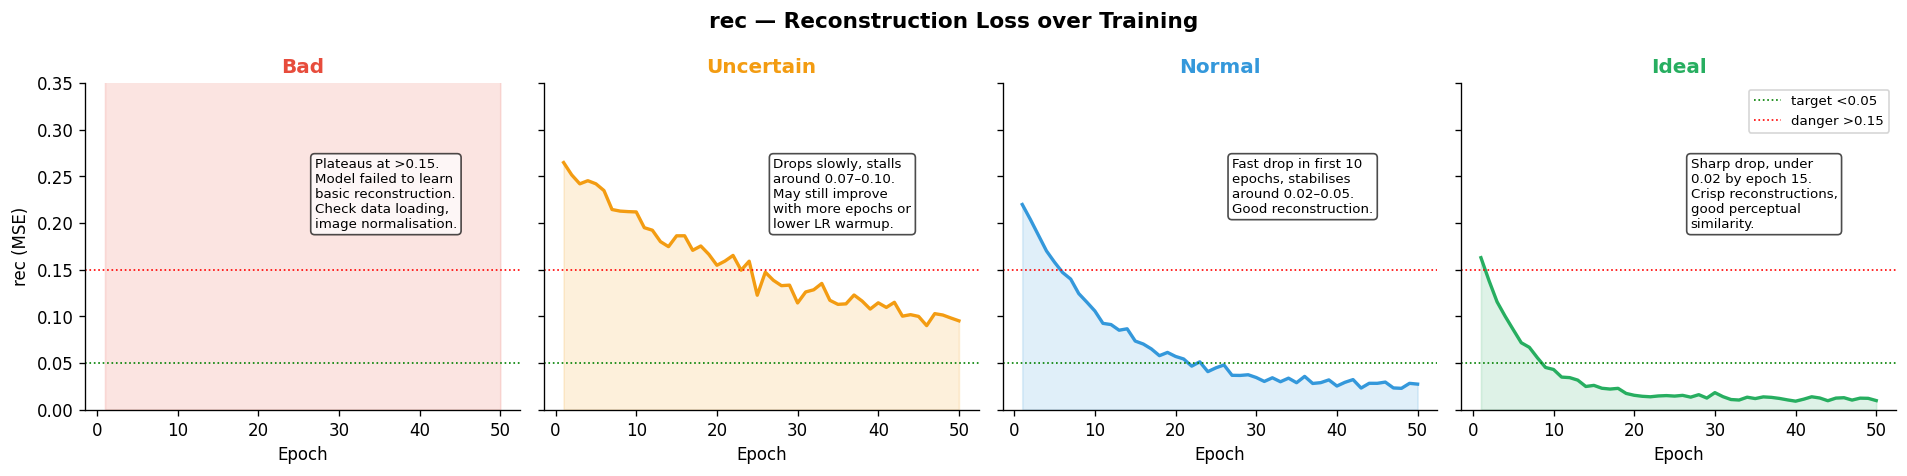

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
fig.suptitle('rec — Reconstruction Loss over Training', fontsize=13, fontweight='bold')

scenarios = {
    'Bad': {
        'color': COLORS['bad'],
        'curve': lambda e: 0.25 * np.exp(-0.005 * e) + 0.18 + 0.01 * np.random.randn(len(e)),
        'desc': 'Plateaus at >0.15.\nModel failed to learn\nbasic reconstruction.\nCheck data loading,\nimage normalisation.'
    },
    'Uncertain': {
        'color': COLORS['uncertain'],
        'curve': lambda e: 0.20 * np.exp(-0.04 * e) + 0.07 + 0.008 * np.random.randn(len(e)),
        'desc': 'Drops slowly, stalls\naround 0.07–0.10.\nMay still improve\nwith more epochs or\nlower LR warmup.'
    },
    'Normal': {
        'color': COLORS['normal'],
        'curve': lambda e: 0.22 * np.exp(-0.10 * e) + 0.025 + 0.003 * np.random.randn(len(e)),
        'desc': 'Fast drop in first 10\nepochs, stabilises\naround 0.02–0.05.\nGood reconstruction.'
    },
    'Ideal': {
        'color': COLORS['ideal'],
        'curve': lambda e: 0.18 * np.exp(-0.18 * e) + 0.012 + 0.002 * np.random.randn(len(e)),
        'desc': 'Sharp drop, under\n0.02 by epoch 15.\nCrisp reconstructions,\ngood perceptual\nsimilarity.'
    }
}

np.random.seed(42)
for ax, (name, s) in zip(axes, scenarios.items()):
    vals = np.clip(s['curve'](EPOCHS), 0.001, 0.4)
    ax.plot(EPOCHS, vals, color=s['color'], lw=2)
    ax.fill_between(EPOCHS, vals, alpha=0.15, color=s['color'])
    ax.axhline(0.05, color='green', linestyle=':', lw=1, label='target <0.05')
    ax.axhline(0.15, color='red', linestyle=':', lw=1, label='danger >0.15')
    ax.set_title(name, color=s['color'], fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylim(0, 0.35)
    ax.text(27, 0.27, s['desc'], fontsize=8, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

axes[0].set_ylabel('rec (MSE)')
axes[3].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig('../results/metric_rec.png', bbox_inches='tight')
plt.show()

---
## 1b. `probe_c` and `probe_e` — Linear Probe AUC

**What they are:** A small linear classifier (logistic regression) trained on the **frozen latent vectors** from each disease head. AUC measures how well the latent encodes that disease.  

- `probe_c` = does the **cardiomegaly head** latent predict cardiomegaly labels?
- `probe_e` = does the **effusion head** latent predict effusion labels?

**Why it matters:** AUC=0.5 → random chance (head encodes nothing useful). AUC=1.0 → perfect encoding.  
**Gate G1:** Both must exceed **0.75** before the model is considered to have learned disease representations.

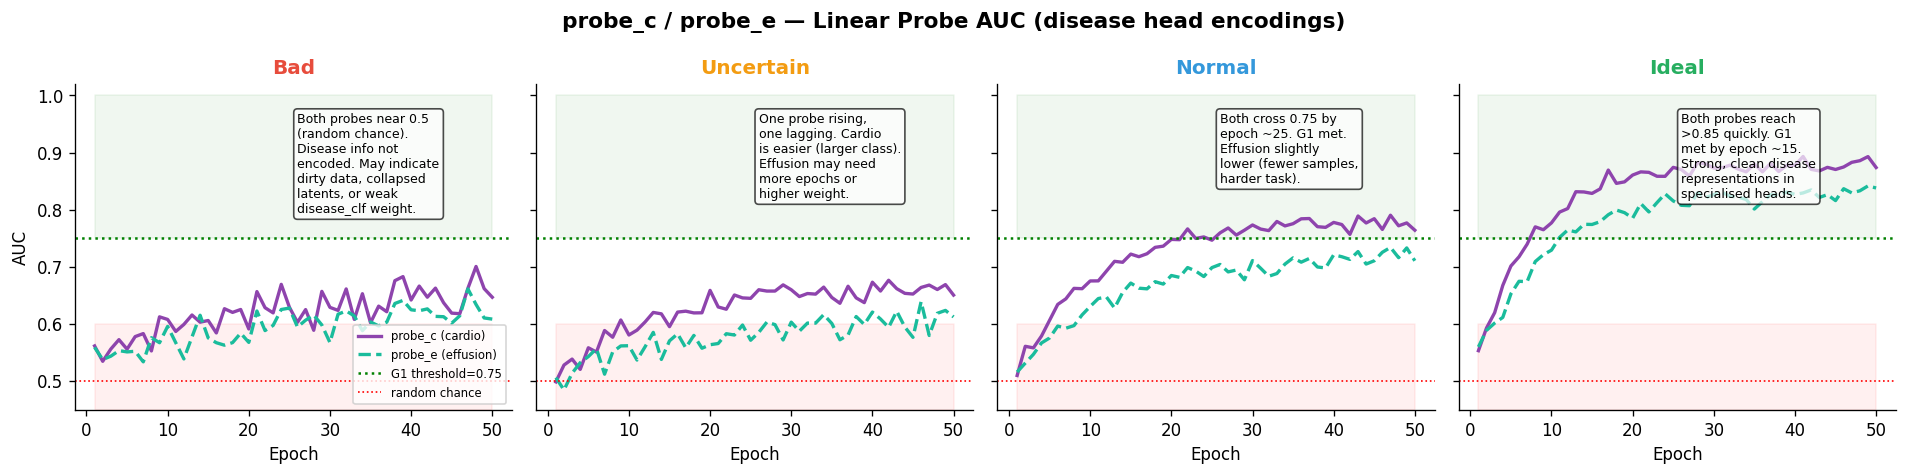

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
fig.suptitle('probe_c / probe_e — Linear Probe AUC (disease head encodings)', fontsize=13, fontweight='bold')

np.random.seed(7)
probe_scenarios = {
    'Bad': {
        'color': COLORS['bad'],
        'c': lambda e: 0.5 + 0.04 * np.log(e+1) + 0.02 * np.random.randn(len(e)),
        'e': lambda e: 0.5 + 0.03 * np.log(e+1) + 0.02 * np.random.randn(len(e)),
        'desc': 'Both probes near 0.5\n(random chance).\nDisease info not\nencoded. May indicate\ndirty data, collapsed\nlatents, or weak\ndisease_clf weight.'
    },
    'Uncertain': {
        'color': COLORS['uncertain'],
        'c': lambda e: 0.5 + 0.18 * (1 - np.exp(-e/15)) + 0.015 * np.random.randn(len(e)),
        'e': lambda e: 0.5 + 0.12 * (1 - np.exp(-e/20)) + 0.015 * np.random.randn(len(e)),
        'desc': 'One probe rising,\none lagging. Cardio\nis easier (larger class).\nEffusion may need\nmore epochs or\nhigher weight.'
    },
    'Normal': {
        'color': COLORS['normal'],
        'c': lambda e: np.clip(0.5 + 0.28 * (1 - np.exp(-e/10)) + 0.01 * np.random.randn(len(e)), 0, 1),
        'e': lambda e: np.clip(0.5 + 0.22 * (1 - np.exp(-e/12)) + 0.01 * np.random.randn(len(e)), 0, 1),
        'desc': 'Both cross 0.75 by\nepoch ~25. G1 met.\nEffusion slightly\nlower (fewer samples,\nharder task).'
    },
    'Ideal': {
        'color': COLORS['ideal'],
        'c': lambda e: np.clip(0.5 + 0.38 * (1 - np.exp(-e/7)) + 0.008 * np.random.randn(len(e)), 0, 1),
        'e': lambda e: np.clip(0.5 + 0.33 * (1 - np.exp(-e/8)) + 0.008 * np.random.randn(len(e)), 0, 1),
        'desc': 'Both probes reach\n>0.85 quickly. G1\nmet by epoch ~15.\nStrong, clean disease\nrepresentations in\nspecialised heads.'
    }
}

for ax, (name, s) in zip(axes, probe_scenarios.items()):
    c_vals = np.clip(s['c'](EPOCHS), 0.45, 1.0)
    e_vals = np.clip(s['e'](EPOCHS), 0.45, 1.0)
    ax.plot(EPOCHS, c_vals, color='#8e44ad', lw=2, label='probe_c (cardio)')
    ax.plot(EPOCHS, e_vals, color='#1abc9c', lw=2, linestyle='--', label='probe_e (effusion)')
    ax.axhline(0.75, color='green', linestyle=':', lw=1.5, label='G1 threshold=0.75')
    ax.axhline(0.5, color='red', linestyle=':', lw=1, label='random chance')
    ax.fill_between(EPOCHS, 0.75, 1.0, alpha=0.06, color='green')
    ax.fill_between(EPOCHS, 0.45, 0.60, alpha=0.06, color='red')
    ax.set_title(name, color=s['color'], fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylim(0.45, 1.02)
    ax.text(26, 0.97, s['desc'], fontsize=7.5, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

axes[0].set_ylabel('AUC')
axes[0].legend(loc='lower right', fontsize=7)
plt.tight_layout()
plt.savefig('../results/metric_probes.png', bbox_inches='tight')
plt.show()

---
## 1c. `xhead` — Cross-Head Leakage Score

**What it is:** Average of two cross-probes:
- AUC of predicting *cardiomegaly* from the **effusion head** latent  
- AUC of predicting *effusion* from the **cardiomegaly head** latent  

So: `xhead = 0.5 × (AUC_c→e + AUC_e→c)`

**Why it matters:** If `xhead` is high, the heads are **sharing information** — the model hasn't disentangled the two diseases. A perfectly disentangled model would have `xhead ≈ 0.5` (each head can't predict the other's disease). `xhead > 0.75` means the heads are basically the same.  
**Gate G2:** Must be **< 0.65** (cross-prediction is near random).

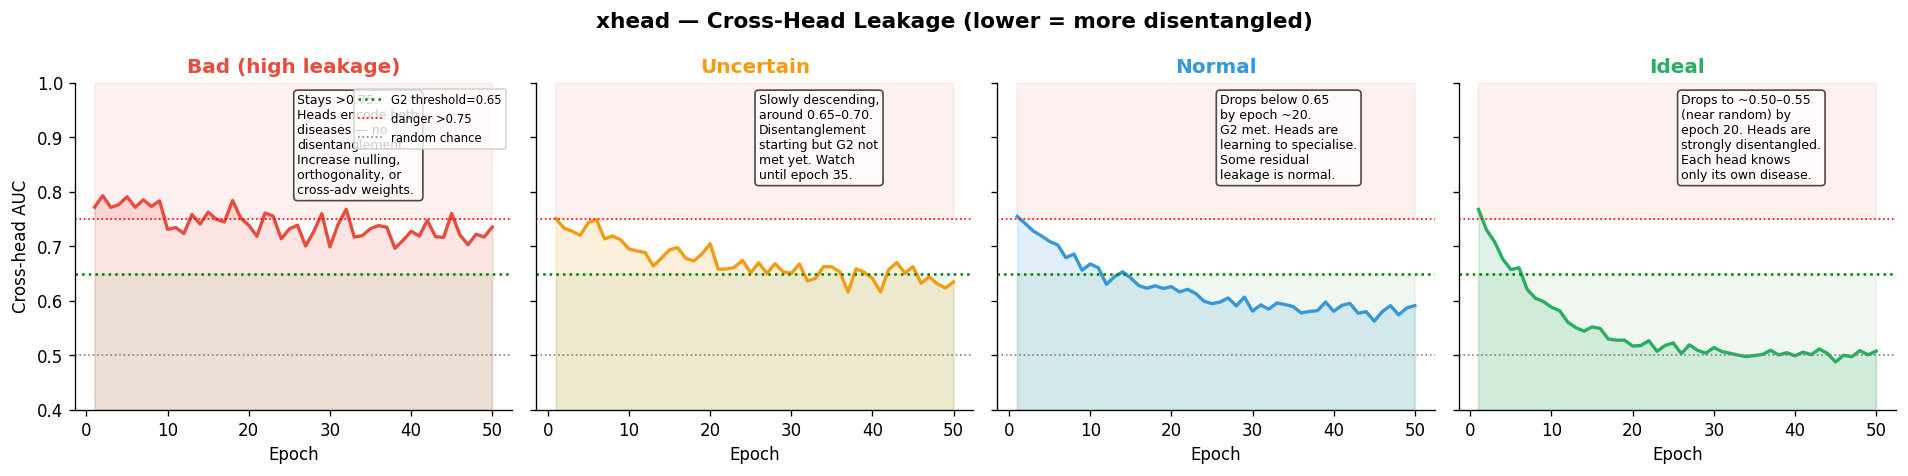

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
fig.suptitle('xhead — Cross-Head Leakage (lower = more disentangled)', fontsize=13, fontweight='bold')

np.random.seed(13)
xhead_scenarios = {
    'Bad (high leakage)': {
        'color': COLORS['bad'],
        'curve': lambda e: 0.80 - 0.02 * np.log(e+1) + 0.02 * np.random.randn(len(e)),
        'desc': 'Stays >0.75.\nHeads encode both\ndiseases — no\ndisentanglement.\nIncrease nulling,\northogonality, or\ncross-adv weights.'
    },
    'Uncertain': {
        'color': COLORS['uncertain'],
        'curve': lambda e: 0.75 - 0.12 * (1 - np.exp(-e/20)) + 0.015 * np.random.randn(len(e)),
        'desc': 'Slowly descending,\naround 0.65–0.70.\nDisentanglement\nstarting but G2 not\nmet yet. Watch\nuntil epoch 35.'
    },
    'Normal': {
        'color': COLORS['normal'],
        'curve': lambda e: np.clip(0.78 - 0.20 * (1 - np.exp(-e/12)) + 0.01 * np.random.randn(len(e)), 0.4, 1),
        'desc': 'Drops below 0.65\nby epoch ~20.\nG2 met. Heads are\nlearning to specialise.\nSome residual\nleakage is normal.'
    },
    'Ideal': {
        'color': COLORS['ideal'],
        'curve': lambda e: np.clip(0.80 - 0.30 * (1 - np.exp(-e/8)) + 0.008 * np.random.randn(len(e)), 0.4, 1),
        'desc': 'Drops to ~0.50–0.55\n(near random) by\nepoch 20. Heads are\nstrongly disentangled.\nEach head knows\nonly its own disease.'
    }
}

for ax, (name, s) in zip(axes, xhead_scenarios.items()):
    vals = np.clip(s['curve'](EPOCHS), 0.4, 1.0)
    ax.plot(EPOCHS, vals, color=s['color'], lw=2)
    ax.fill_between(EPOCHS, vals, alpha=0.15, color=s['color'])
    ax.axhline(0.65, color='green', linestyle=':', lw=1.5, label='G2 threshold=0.65')
    ax.axhline(0.75, color='red', linestyle=':', lw=1, label='danger >0.75')
    ax.axhline(0.50, color='gray', linestyle=':', lw=1, label='random chance')
    ax.fill_between(EPOCHS, 0.4, 0.65, alpha=0.06, color='green')
    ax.fill_between(EPOCHS, 0.75, 1.0, alpha=0.06, color='red')
    ax.set_title(name, color=s['color'], fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylim(0.4, 1.0)
    ax.text(26, 0.98, s['desc'], fontsize=7.5, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

axes[0].set_ylabel('Cross-head AUC')
axes[0].legend(loc='upper right', fontsize=7)
plt.tight_layout()
plt.savefig('../results/metric_xhead.png', bbox_inches='tight')
plt.show()

---
## 1d. Individual Loss Components
These are not in the one-liner but are in WandB. Knowing what to expect from each helps diagnose the one-liner.

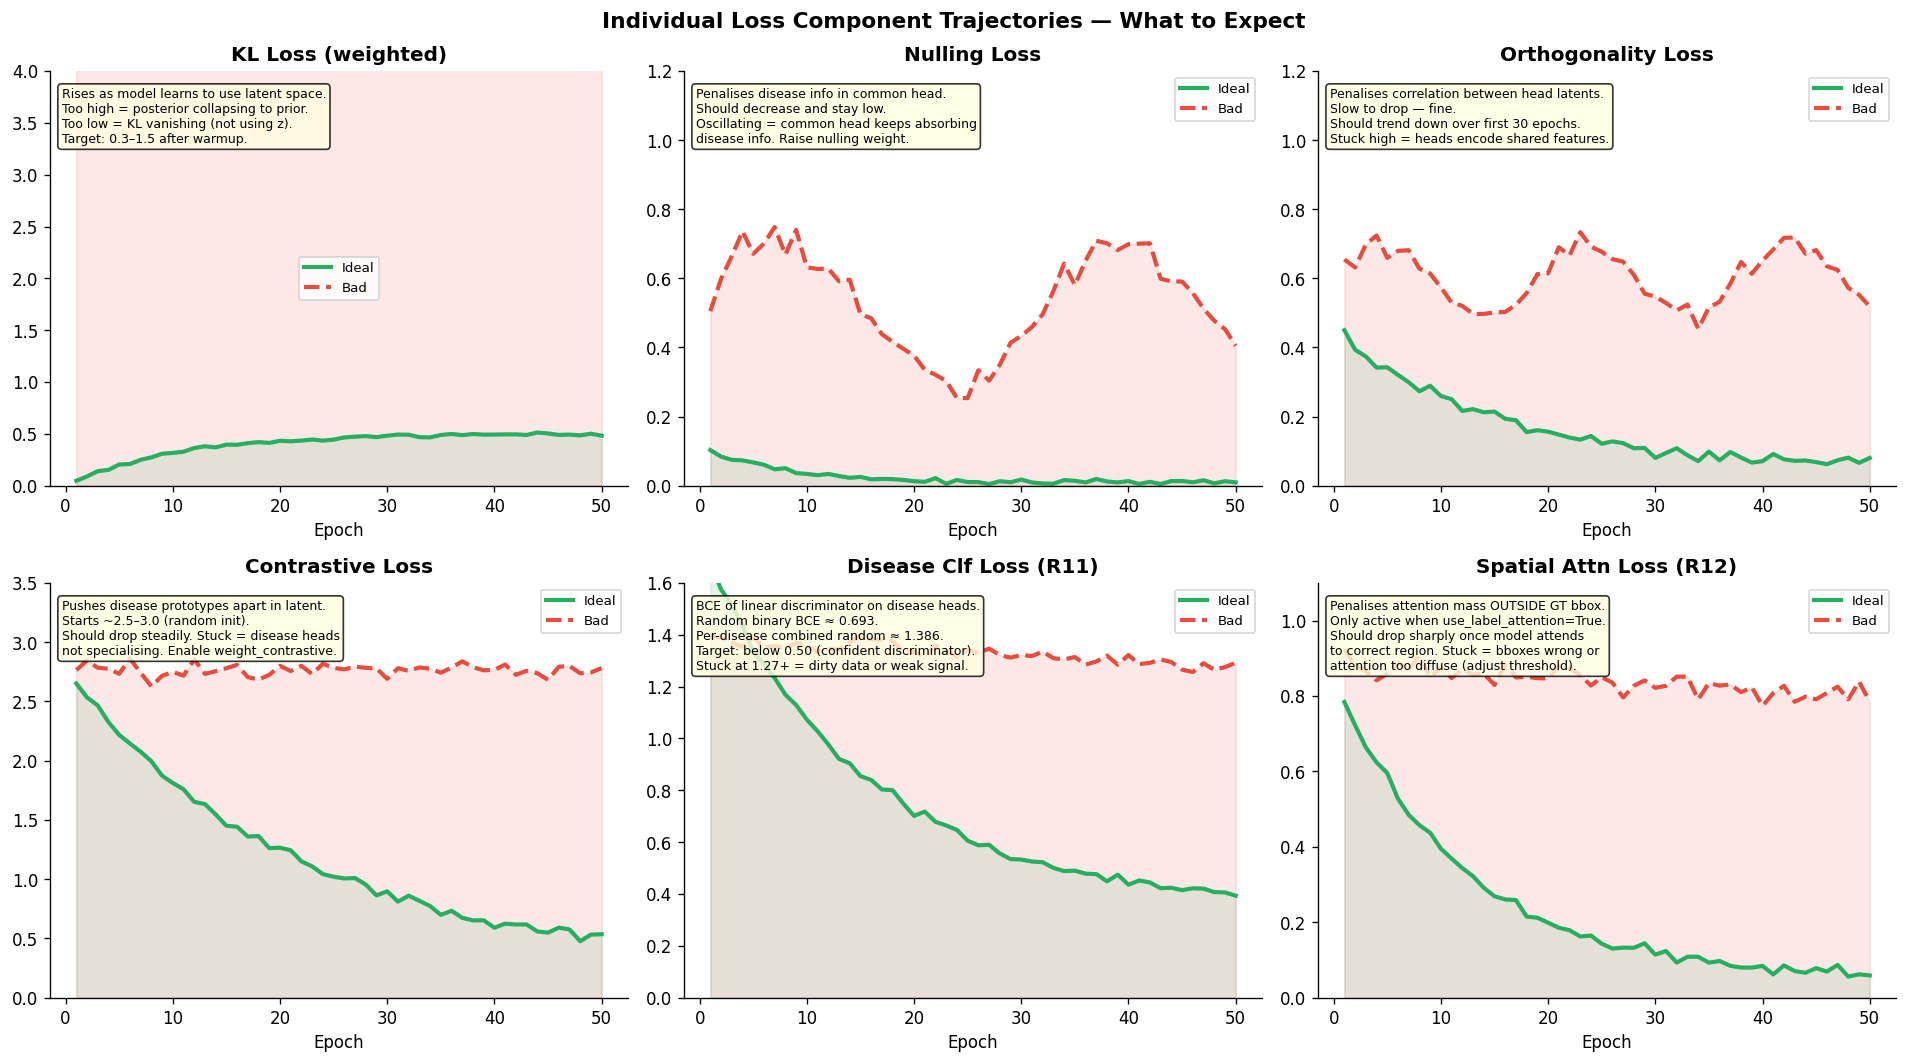

In [7]:
np.random.seed(21)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Individual Loss Component Trajectories — What to Expect', fontsize=13, fontweight='bold')

loss_components = [
    {
        'name': 'KL Loss (weighted)', 'ax': axes[0,0],
        'ideal': lambda e: np.clip(0.5 * (1 - np.exp(-e/10)) + 0.01*np.random.randn(len(e)), 0, 2),
        'bad':   lambda e: np.clip(3.0 * np.exp(-0.01*e) + 2.5 + 0.05*np.random.randn(len(e)), 0, 6),
        'note': 'Rises as model learns to use latent space.\nToo high = posterior collapsing to prior.\nToo low = KL vanishing (not using z).\nTarget: 0.3–1.5 after warmup.',
        'ymax': 4.0
    },
    {
        'name': 'Nulling Loss', 'ax': axes[0,1],
        'ideal': lambda e: np.clip(0.1 * np.exp(-e/8) + 0.01 + 0.005*np.random.randn(len(e)), 0, 1),
        'bad':   lambda e: np.clip(0.5 + 0.2*np.sin(e/5) + 0.03*np.random.randn(len(e)), 0, 1.5),
        'note': 'Penalises disease info in common head.\nShould decrease and stay low.\nOscillating = common head keeps absorbing\ndisease info. Raise nulling weight.',
        'ymax': 1.2
    },
    {
        'name': 'Orthogonality Loss', 'ax': axes[0,2],
        'ideal': lambda e: np.clip(0.4 * np.exp(-e/15) + 0.05 + 0.01*np.random.randn(len(e)), 0, 1),
        'bad':   lambda e: np.clip(0.6 + 0.1*np.sin(e/3) + 0.02*np.random.randn(len(e)), 0, 1.5),
        'note': 'Penalises correlation between head latents.\nSlow to drop — fine.\nShould trend down over first 30 epochs.\nStuck high = heads encode shared features.',
        'ymax': 1.2
    },
    {
        'name': 'Contrastive Loss', 'ax': axes[1,0],
        'ideal': lambda e: np.clip(2.5 * np.exp(-e/20) + 0.3 + 0.03*np.random.randn(len(e)), 0, 3),
        'bad':   lambda e: np.clip(2.8 - 0.001*e + 0.05*np.random.randn(len(e)), 0, 3.5),
        'note': 'Pushes disease prototypes apart in latent.\nStarts ~2.5–3.0 (random init).\nShould drop steadily. Stuck = disease heads\nnot specialising. Enable weight_contrastive.',
        'ymax': 3.5
    },
    {
        'name': 'Disease Clf Loss (R11)', 'ax': axes[1,1],
        'ideal': lambda e: np.clip(1.4 * np.exp(-e/15) + 0.35 + 0.01*np.random.randn(len(e)), 0, 2),
        'bad':   lambda e: np.clip(1.38 - 0.002*e + 0.02*np.random.randn(len(e)), 1.0, 1.5),
        'note': 'BCE of linear discriminator on disease heads.\nRandom binary BCE ≈ 0.693.\nPer-disease combined random ≈ 1.386.\nTarget: below 0.50 (confident discriminator).\nStuck at 1.27+ = dirty data or weak signal.',
        'ymax': 1.6
    },
    {
        'name': 'Spatial Attn Loss (R12)', 'ax': axes[1,2],
        'ideal': lambda e: np.clip(0.8 * np.exp(-e/12) + 0.05 + 0.008*np.random.randn(len(e)), 0, 1),
        'bad':   lambda e: np.clip(0.9 - 0.002*e + 0.02*np.random.randn(len(e)), 0.5, 1.2),
        'note': 'Penalises attention mass OUTSIDE GT bbox.\nOnly active when use_label_attention=True.\nShould drop sharply once model attends\nto correct region. Stuck = bboxes wrong or\nattention too diffuse (adjust threshold).',
        'ymax': 1.1
    }
]

for comp in loss_components:
    ax = comp['ax']
    ideal_vals = comp['ideal'](EPOCHS)
    bad_vals   = comp['bad'](EPOCHS)
    ax.plot(EPOCHS, ideal_vals, color=COLORS['ideal'], lw=2.5, label='Ideal')
    ax.plot(EPOCHS, bad_vals,   color=COLORS['bad'],   lw=2.5, linestyle='--', label='Bad')
    ax.fill_between(EPOCHS, ideal_vals, alpha=0.12, color=COLORS['ideal'])
    ax.fill_between(EPOCHS, bad_vals,   alpha=0.12, color=COLORS['bad'])
    ax.set_title(comp['name'], fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylim(0, comp['ymax'])
    ax.legend(fontsize=8)
    ax.text(0.02, 0.96, comp['note'], transform=ax.transAxes, fontsize=7.5,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('../results/metric_loss_components.png', bbox_inches='tight')
plt.show()

---
# Part 2: PCA Scatter Plots of Disease Heads

These show what the latent space **looks like** in each scenario.

**Setup:**
- Each point is a sample: Normal (grey), Cardiomegaly (purple), Effusion (teal)
- **Left plot:** cardiomegaly head latent PCA
- **Right plot:** effusion head latent PCA

**What we want:**
- In the **cardiomegaly head**: purple far from grey/teal, but grey and teal overlap
- In the **effusion head**: teal far from grey/purple, but grey and purple overlap
- Common information (anatomy, patient ID) should be in the **common head** (not shown here)

---
### ⚠ Common Misconception: We Do NOT Expect Orthogonal Subspaces in PCA

A natural but **incorrect** intuition is: *"if the orthogonality loss is working, shouldn't the Effusion cluster lie horizontally and the Cardiomegaly cluster lie vertically in the PCA plot?"*

**No — and here is why:**

1. **PCA finds maximum-variance directions, not disease directions.** The principal components are determined by the overall covariance of all samples. Even if the two disease heads are perfectly orthogonal in latent space, PCA has no obligation to align its axes with those disease directions.

2. **Orthogonality is a property of latent dimensions, not cluster positions.** The orthogonality loss penalises correlation between the cardiomegaly head's latent code and the effusion head's latent code *across samples*. It does not enforce that the PCA projection of those latents points in perpendicular directions.

3. **Diseases co-occur.** A patient can have both cardiomegaly and effusion simultaneously. In a *joint* PCA of both disease heads, the two clusters will naturally overlap in the shared disease region. A low silhouette score (~0.13) on a joint "Disease Only" PCA is **expected and does not indicate failure**.

**What the PCA plots DO tell you (correctly):**
- In the **cardiomegaly head PCA**: does the cardiomegaly class form a distinct cluster? → `probe_c` signal
- In the **effusion head PCA**: does the effusion class form a distinct cluster? → `probe_e` signal
- Does the *other* disease bleed into a head it should not? → `xhead` signal

**The correct diagnostic is per-head PCA (as shown below), not a joint PCA of both diseases overlaid.**

In [ ]:
from sklearn.cross_decomposition import PLSCanonical
import warnings

np.random.seed(42)

# ── Synthetic latents: bad = correlated heads, ideal = uncorrelated heads ──────
D = 16
N_samples = 300  # all classes pooled

def make_head_pair(scenario):
    """
    Returns (z_c, z_e) each of shape (N_samples, D).
    bad:   shared latent factor drives both heads  → correlated
    ideal: heads are statistically independent     → orthogonal
    """
    shared = np.random.randn(N_samples, D // 2)  # shared structure

    if scenario == 'bad':
        # Both heads largely driven by the same shared factor
        z_c = np.hstack([shared + 0.3 * np.random.randn(N_samples, D // 2),
                         np.random.randn(N_samples, D // 2)])
        z_e = np.hstack([shared + 0.3 * np.random.randn(N_samples, D // 2),
                         np.random.randn(N_samples, D // 2)])
    elif scenario == 'uncertain':
        # Partial sharing: first quarter of dims correlated
        z_c = np.hstack([shared[:, :D//4] + 0.5 * np.random.randn(N_samples, D//4),
                         np.random.randn(N_samples, 3 * D // 4)])
        z_e = np.hstack([shared[:, :D//4] + 0.5 * np.random.randn(N_samples, D//4),
                         np.random.randn(N_samples, 3 * D // 4)])
    else:  # ideal
        # Completely independent
        z_c = np.random.randn(N_samples, D)
        z_e = np.random.randn(N_samples, D)

    # Z-score each head (as the model would approximately produce)
    z_c = (z_c - z_c.mean(0)) / (z_c.std(0) + 1e-8)
    z_e = (z_e - z_e.mean(0)) / (z_e.std(0) + 1e-8)
    return z_c, z_e


def cross_corr_matrix(z_c, z_e):
    """D_c × D_e matrix of Pearson correlations."""
    n = z_c.shape[0]
    zc = (z_c - z_c.mean(0)) / (z_c.std(0) + 1e-8)
    ze = (z_e - z_e.mean(0)) / (z_e.std(0) + 1e-8)
    return (zc.T @ ze) / n  # (D, D)


def top_canonical_correlations(z_c, z_e, n_components=8):
    """PLS-based canonical correlations (robust for small N)."""
    n_comp = min(n_components, z_c.shape[1], z_c.shape[0] - 1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        pls = PLSCanonical(n_components=n_comp, max_iter=500)
        pls.fit(z_c, z_e)
    scores_c, scores_e = pls.transform(z_c, z_e)
    # Pearson r for each canonical pair
    corrs = [np.corrcoef(scores_c[:, i], scores_e[:, i])[0, 1]
             for i in range(n_comp)]
    return np.abs(corrs)


# ── Figure layout ──────────────────────────────────────────────────────────────
scenarios = ['bad', 'uncertain', 'ideal']
sc_labels  = ['Bad\n(heads correlated)', 'Uncertain\n(partial sharing)', 'Ideal\n(heads independent)']
sc_colors  = [COLORS['bad'], COLORS['uncertain'], COLORS['ideal']]

fig = plt.figure(figsize=(18, 12))
fig.suptitle('Orthogonality Diagnostics — Cross-Head Correlation Views\n'
             '(These are the correct plots to assess the orthogonality loss)',
             fontsize=13, fontweight='bold')

outer = gridspec.GridSpec(3, 3, figure=fig, hspace=0.55, wspace=0.38)

for col, (sc, label, color) in enumerate(zip(scenarios, sc_labels, sc_colors)):
    z_c, z_e = make_head_pair(sc)
    cc_mat    = cross_corr_matrix(z_c, z_e)
    can_corrs = top_canonical_correlations(z_c, z_e, n_components=8)

    # ── Row 0: Cross-correlation heatmap ──────────────────────────────────────
    ax0 = fig.add_subplot(outer[0, col])
    im = ax0.imshow(cc_mat, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    plt.colorbar(im, ax=ax0, shrink=0.8, label='Pearson r')
    ax0.set_title(f'{label}\nCross-head correlation matrix', color=color,
                  fontweight='bold', fontsize=9)
    ax0.set_xlabel('z_e dimension', fontsize=8)
    ax0.set_ylabel('z_c dimension', fontsize=8)
    ax0.tick_params(labelsize=7)

    # Ideal target box
    mean_abs = np.abs(cc_mat).mean()
    ax0.text(0.5, -0.22, f'mean |r| = {mean_abs:.3f}  {"✓ near 0" if mean_abs < 0.15 else "✗ too high"}',
             transform=ax0.transAxes, ha='center', fontsize=8, color=color, fontweight='bold')

    # ── Row 1: Canonical correlation bar chart ────────────────────────────────
    ax1 = fig.add_subplot(outer[1, col])
    x = np.arange(1, len(can_corrs) + 1)
    bar_colors = ['green' if c < 0.3 else ('orange' if c < 0.6 else 'red') for c in can_corrs]
    ax1.bar(x, can_corrs, color=bar_colors, edgecolor='white', linewidth=1.2)
    ax1.axhline(0.30, color='green',  linestyle=':', lw=1.5, label='target <0.30')
    ax1.axhline(0.60, color='red',    linestyle=':', lw=1.0, label='danger >0.60')
    ax1.set_ylim(0, 1.05)
    ax1.set_xlabel('Canonical pair rank', fontsize=8)
    ax1.set_ylabel('|Canonical correlation|', fontsize=8)
    ax1.set_title('Top canonical correlations (CCA)\n→ low bars = heads are orthogonal',
                  fontsize=8, fontweight='bold')
    ax1.tick_params(labelsize=7)
    if col == 0:
        ax1.legend(fontsize=7, loc='upper right')

    # ── Row 2: Top-1 CCA pair scatter ─────────────────────────────────────────
    ax2 = fig.add_subplot(outer[2, col])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        pls1 = PLSCanonical(n_components=1, max_iter=500)
        pls1.fit(z_c, z_e)
    sc_c, sc_e = pls1.transform(z_c, z_e)
    sc_c, sc_e = sc_c.ravel(), sc_e.ravel()

    r_val = np.corrcoef(sc_c, sc_e)[0, 1]
    ax2.scatter(sc_c, sc_e, alpha=0.25, s=10, color=color, edgecolors='none')

    # Regression line
    m, b = np.polyfit(sc_c, sc_e, 1)
    x_line = np.linspace(sc_c.min(), sc_c.max(), 100)
    ax2.plot(x_line, m * x_line + b, color='black', lw=1.5, linestyle='--', alpha=0.6)

    ax2.set_xlabel('z_c top CCA direction', fontsize=8)
    ax2.set_ylabel('z_e top CCA direction', fontsize=8)
    ax2.set_title(f'Top-1 CCA pair scatter\nr = {r_val:.3f}  '
                  f'{"→ circular (orthogonal) ✓" if abs(r_val) < 0.3 else "→ diagonal (correlated) ✗"}',
                  fontsize=8, fontweight='bold')
    ax2.tick_params(labelsize=7)
    ax2.set_aspect('equal', adjustable='datalim')

plt.savefig('../results/orthogonality_diagnostics.png', bbox_inches='tight')
plt.show()

print()
print('Interpretation guide:')
print('  Heatmap   → ideal: uniformly grey (all |r| near 0); bad: red/blue patches')
print('  CCA bars  → ideal: all bars < 0.3; bad: tall bars on the left')
print('  Scatter   → ideal: circular cloud; bad: elongated diagonal band')


---
## Part 2b: Visualising Orthogonality Between Disease Heads

Since PCA cannot show orthogonality, we need visualisations that directly measure **cross-head correlation**.

Three complementary views:

| View | What it shows | Ideal |
|------|--------------|-------|
| **Cross-head correlation heatmap** | Pearson r between every pair of (z_c[i], z_e[j]) dimensions | All cells grey (near 0) |
| **Canonical Correlation (CCA) bar chart** | Maximum correlation between any linear combination of z_c and z_e | All bars near 0 |
| **Top-1 CCA pair scatter** | Scatter of the single most-correlated projection pair | Circular / no trend |

These directly answer: *"Do the two heads share information?"* — which is exactly what the orthogonality loss targets.

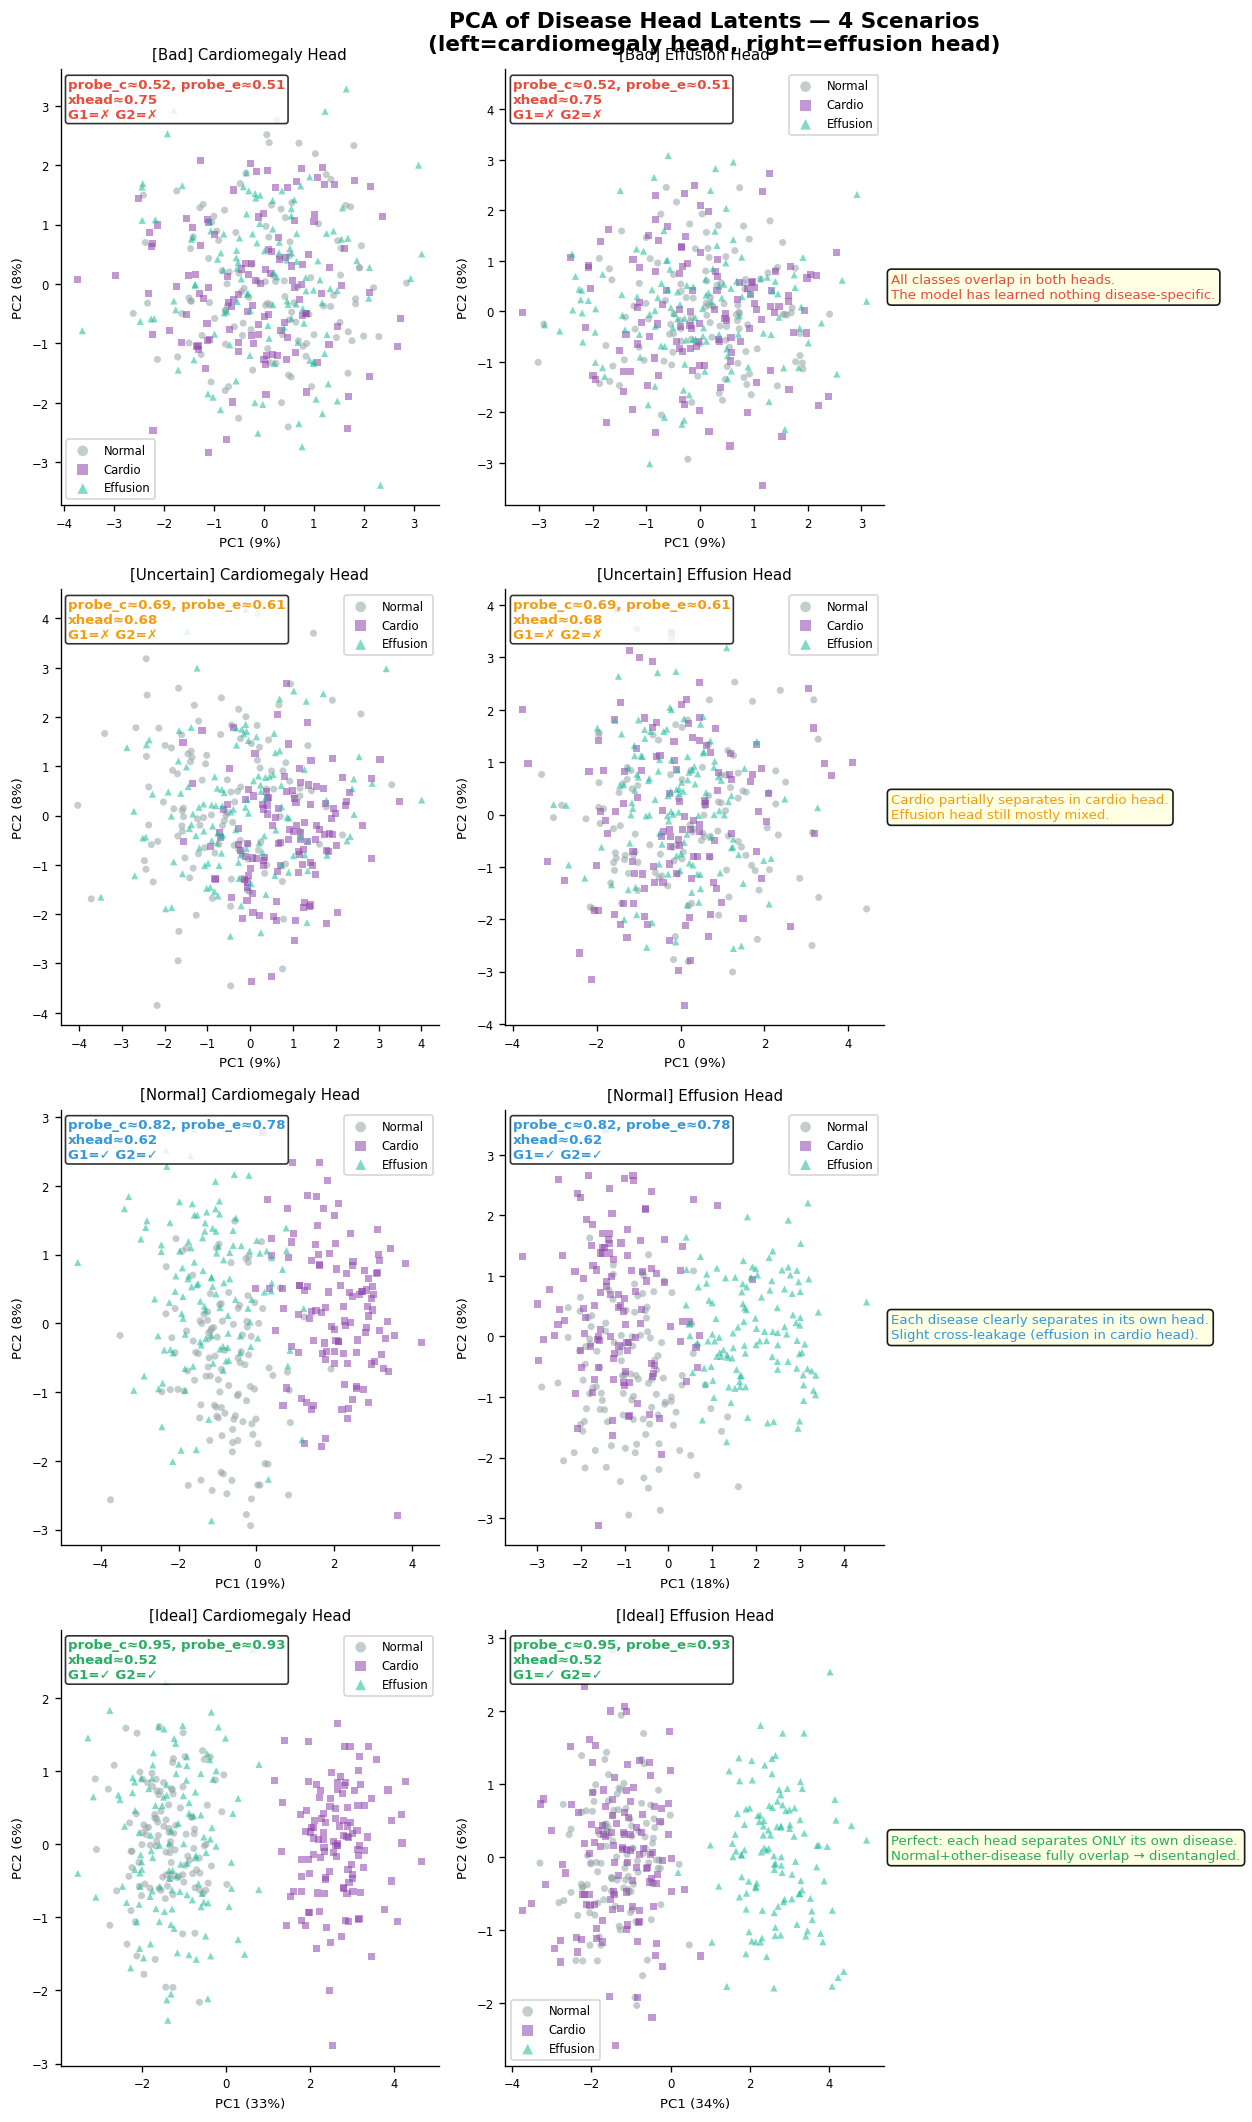

In [8]:
np.random.seed(99)

N = 120  # samples per class

def make_latents(scenario):
    """Synthetic latents for 3 classes in cardiomegaly and effusion heads."""
    D = 16  # latent dim
    
    if scenario == 'bad':
        # Everything collapsed — all classes look the same in both heads
        cardio_head = {
            'normal':   np.random.randn(N, D) * 1.0,
            'cardio':   np.random.randn(N, D) * 1.0,
            'effusion': np.random.randn(N, D) * 1.0,
        }
        eff_head = {
            'normal':   np.random.randn(N, D) * 1.0,
            'cardio':   np.random.randn(N, D) * 1.0,
            'effusion': np.random.randn(N, D) * 1.0,
        }
    
    elif scenario == 'uncertain':
        # Cardio head has some separation for cardio; effusion head still mixed
        cardio_shift = np.zeros(D); cardio_shift[0] = 1.5
        cardio_head = {
            'normal':   np.random.randn(N, D) * 1.2,
            'cardio':   np.random.randn(N, D) * 1.0 + cardio_shift,
            'effusion': np.random.randn(N, D) * 1.2 + 0.3 * cardio_shift,
        }
        eff_head = {
            'normal':   np.random.randn(N, D) * 1.2,
            'cardio':   np.random.randn(N, D) * 1.2,
            'effusion': np.random.randn(N, D) * 1.0 + 0.8 * np.array([0,1.2]+[0]*(D-2)),
        }
    
    elif scenario == 'normal':
        # Good separation in own head; some leakage (effusion slightly separates in cardio head)
        cardio_shift = np.zeros(D); cardio_shift[0] = 3.0
        eff_shift    = np.zeros(D); eff_shift[1]    = 3.0
        cardio_head = {
            'normal':   np.random.randn(N, D) * 0.9,
            'cardio':   np.random.randn(N, D) * 0.8 + cardio_shift,
            'effusion': np.random.randn(N, D) * 1.0 + 0.4 * eff_shift,  # slight leak
        }
        eff_head = {
            'normal':   np.random.randn(N, D) * 0.9,
            'cardio':   np.random.randn(N, D) * 1.0 + 0.4 * cardio_shift,  # slight leak
            'effusion': np.random.randn(N, D) * 0.8 + eff_shift,
        }
    
    else:  # ideal
        # Perfect separation in own head; NO separation of other class
        cardio_shift = np.zeros(D); cardio_shift[0] = 4.0
        eff_shift    = np.zeros(D); eff_shift[1]    = 4.0
        cardio_head = {
            'normal':   np.random.randn(N, D) * 0.7,
            'cardio':   np.random.randn(N, D) * 0.7 + cardio_shift,
            'effusion': np.random.randn(N, D) * 0.8,  # no separation
        }
        eff_head = {
            'normal':   np.random.randn(N, D) * 0.7,
            'cardio':   np.random.randn(N, D) * 0.8,  # no separation
            'effusion': np.random.randn(N, D) * 0.7 + eff_shift,
        }
    
    return cardio_head, eff_head


def plot_pca_scatter(ax, latents_dict, title, colors_map):
    all_data = np.vstack([latents_dict['normal'], latents_dict['cardio'], latents_dict['effusion']])
    labels = (['Normal']*N + ['Cardio']*N + ['Effusion']*N)
    pca = PCA(n_components=2)
    reduced = pca.fit_transform(all_data)
    
    for cls, color, marker in [('Normal', colors_map['normal'], 'o'),
                                 ('Cardio', colors_map['cardio'], 's'),
                                 ('Effusion', colors_map['effusion'], '^')]:
        mask = np.array(labels) == cls
        ax.scatter(reduced[mask, 0], reduced[mask, 1], c=color, label=cls,
                   alpha=0.55, s=18, marker=marker, edgecolors='none')
    
    var_explained = pca.explained_variance_ratio_
    ax.set_xlabel(f'PC1 ({var_explained[0]*100:.0f}%)', fontsize=8)
    ax.set_ylabel(f'PC2 ({var_explained[1]*100:.0f}%)', fontsize=8)
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7, markerscale=1.5)
    ax.tick_params(labelsize=7)


CLASS_COLORS = {'normal': '#95a5a6', 'cardio': '#8e44ad', 'effusion': '#1abc9c'}
scenarios = ['bad', 'uncertain', 'normal', 'ideal']
scenario_labels = ['Bad', 'Uncertain', 'Normal', 'Ideal']

fig, axes = plt.subplots(4, 2, figsize=(12, 18))
fig.suptitle('PCA of Disease Head Latents — 4 Scenarios\n(left=cardiomegaly head, right=effusion head)',
             fontsize=13, fontweight='bold')

scenario_descs = {
    'bad':      ('probe_c≈0.52, probe_e≈0.51\nxhead≈0.75\nG1=✗ G2=✗',
                 'All classes overlap in both heads.\nThe model has learned nothing disease-specific.'),
    'uncertain': ('probe_c≈0.69, probe_e≈0.61\nxhead≈0.68\nG1=✗ G2=✗',
                  'Cardio partially separates in cardio head.\nEffusion head still mostly mixed.'),
    'normal':   ('probe_c≈0.82, probe_e≈0.78\nxhead≈0.62\nG1=✓ G2=✓',
                 'Each disease clearly separates in its own head.\nSlight cross-leakage (effusion in cardio head).'),
    'ideal':    ('probe_c≈0.95, probe_e≈0.93\nxhead≈0.52\nG1=✓ G2=✓',
                 'Perfect: each head separates ONLY its own disease.\nNormal+other-disease fully overlap → disentangled.')
}

for row, (sc, sc_label) in enumerate(zip(scenarios, scenario_labels)):
    cardio_h, eff_h = make_latents(sc)
    
    plot_pca_scatter(axes[row, 0], cardio_h, f'[{sc_label}] Cardiomegaly Head', CLASS_COLORS)
    plot_pca_scatter(axes[row, 1], eff_h,    f'[{sc_label}] Effusion Head',      CLASS_COLORS)
    
    metrics_str, desc_str = scenario_descs[sc]
    color = list(COLORS.values())[row]
    
    for ax in axes[row]:
        ax.text(0.02, 0.98, metrics_str, transform=ax.transAxes, fontsize=8,
                verticalalignment='top', color=color, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    axes[row, 1].text(1.02, 0.5, desc_str, transform=axes[row, 1].transAxes,
                      fontsize=8, verticalalignment='center', color=color,
                      bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.9))

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig('../results/pca_scenarios.png', bbox_inches='tight')
plt.show()

---
## Part 2c: Prototype-Vector Compass (angle-annotated)

The orthogonality loss penalises the cosine similarity between two cross-head prototypes:

- **proto_cardio** = mean of the *cardiomegaly head* on cardiomegaly-positive samples
- **proto_effusion** = mean of the *effusion head* on effusion-positive samples

Because `z_channels_disease = 2`, both prototypes live in **ℝ²** and can be drawn as arrows
in the same space. The angle between them is annotated directly.

| Scenario | What the arrows look like | Angle |
|----------|--------------------------|-------|
| **Bad** | Both arrows nearly parallel — heads encode the same direction | ≈ 5–10° |
| **Uncertain** | Arrows at an oblique angle — partial decorrelation | ≈ 40–50° |
| **Normal** | Arrows mostly orthogonal with residual pull | ≈ 70–80° |
| **Ideal** | Arrows exactly orthogonal — proto_cosine_sq → 0 | ≈ 90° |

The scatter in the background shows where all three classes land in each head.
Note that in the ideal case the *other* disease class (e.g. effusion in the cardio head)
collapses onto Normal — its arrow is near origin and therefore irrelevant for orthogonality.

In [ ]:
np.random.seed(7)
D2 = 2  # z_channels_disease = 2 in the actual model — no PCA needed


def make_cross_head_latents(scenario):
    """Return per-head 2D latents configured so the CROSS-HEAD proto angle
    matches the scenario label.  Each head's disease class is set up so that:
      - cardio head: cardio class is displaced in c_dir; effusion class near origin
      - effusion head: effusion class is displaced in e_dir; cardio class near origin
    The angle between c_dir and e_dir encodes the scenario.
    """
    rng = np.random.default_rng(7)
    n   = 120
    sd  = 0.70

    # Disease prototype directions per scenario (both unit-scaled to magnitude ~3)
    mag = 3.0
    dirs = {
        #              c_dir (cardio head, cardio class)  e_dir (effusion head, effusion class)
        'bad':       (np.array([1.0,  0.08]) * mag,   np.array([0.98, 0.10]) * mag),  # ~7°
        'uncertain': (np.array([1.0,  0.0])  * mag,   np.array([0.70, 0.71]) * mag),  # 45°
        'normal':    (np.array([1.0,  0.0])  * mag,   np.array([0.25, 0.97]) * mag),  # 76°
        'ideal':     (np.array([1.0,  0.0])  * mag,   np.array([0.0,  1.0])  * mag),  # 90°
    }
    c_dir, e_dir = dirs[scenario]

    # Cardiomegaly head: cardio → c_dir; effusion and normal → near origin
    c_head = {
        'normal':   rng.standard_normal((n, D2)) * sd,
        'cardio':   rng.standard_normal((n, D2)) * sd + c_dir,
        'effusion': rng.standard_normal((n, D2)) * sd * 0.9,   # ≈ origin
    }
    # Effusion head: effusion → e_dir; cardio and normal → near origin
    e_head = {
        'normal':   rng.standard_normal((n, D2)) * sd,
        'cardio':   rng.standard_normal((n, D2)) * sd * 0.9,   # ≈ origin
        'effusion': rng.standard_normal((n, D2)) * sd + e_dir,
    }
    return c_head, e_head, c_dir, e_dir


def cross_head_angle(c_dir, e_dir):
    def unit(v): n = np.linalg.norm(v); return v / n if n > 1e-9 else v
    cos = np.clip(np.dot(unit(c_dir), unit(e_dir)), -1, 1)
    return np.degrees(np.arccos(abs(cos)))


def plot_compass(ax, c_head, e_head, c_dir, e_dir, title, sc_color):
    """Scatter both heads + draw cross-head prototype arrows + annotate angle."""
    # Background scatter
    cls_cfg = [
        ('normal',   c_head, '#bdc3c7', 'o', 0.25, 'Normal (cardio head)'),
        ('cardio',   c_head, '#8e44ad', 's', 0.40, 'Cardio (cardio head)'),
        ('effusion', c_head, '#c39bd3', '^', 0.25, 'Effusion (cardio head)'),
        ('normal',   e_head, '#aab7b8', 'o', 0.25, 'Normal (eff head)'),
        ('cardio',   e_head, '#76d7c4', 's', 0.25, 'Cardio (eff head)'),
        ('effusion', e_head, '#1abc9c', '^', 0.40, 'Effusion (eff head)'),
    ]
    for cls, head, color, marker, alpha, lbl in cls_cfg:
        pts = head[cls]
        ax.scatter(pts[:, 0], pts[:, 1], c=color, marker=marker,
                   alpha=alpha, s=12, edgecolors='none', label=lbl)

    # Cross-head prototype arrows
    proto_c = c_head['cardio'].mean(0)    # from cardiomegaly head
    proto_e = e_head['effusion'].mean(0)  # from effusion head

    akw = dict(width=0.06, head_width=0.25, head_length=0.22,
               length_includes_head=True, zorder=6)
    ax.arrow(0, 0, proto_c[0], proto_c[1], color='#8e44ad', **akw,
             label='proto_cardio (cardio head)')
    ax.arrow(0, 0, proto_e[0], proto_e[1], color='#1abc9c', **akw,
             label='proto_effusion (eff head)')
    ax.scatter([0], [0], c='k', s=35, zorder=7)

    angle = cross_head_angle(proto_c, proto_e)
    angle_color = '#27ae60' if angle >= 82 else ('#3498db' if angle >= 65 else
                  ('#f39c12' if angle >= 35 else '#e74c3c'))
    ax.text(0.97, 0.97,
            f'cross-head\nangle = {angle:.0f}°\n(want ≈ 90°)',
            transform=ax.transAxes, fontsize=8,
            ha='right', va='top', color=angle_color, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.9))

    ax.axhline(0, color='k', lw=0.4, alpha=0.3)
    ax.axvline(0, color='k', lw=0.4, alpha=0.3)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=9)
    ax.tick_params(labelsize=7)

    # Compact legend
    ax.plot([], [], color='#8e44ad', lw=2.5, label='→ proto_cardio')
    ax.plot([], [], color='#1abc9c', lw=2.5, label='→ proto_effusion')
    ax.legend(fontsize=6, loc='lower left', ncol=2, handlelength=1.2)


scenarios    = ['bad', 'uncertain', 'normal', 'ideal']
sc_labels    = ['Bad', 'Uncertain', 'Normal', 'Ideal']
sc_colors    = [COLORS['bad'], COLORS['uncertain'], COLORS['normal'], COLORS['ideal']]
sc_subtitles = [
    'Both heads encode disease in\nthe same direction.\nproto_cosine_sq ≈ 1. Loss is large.',
    'Partial separation.\nAngle ~45°. Both heads\nstill partly entangled.',
    'Nearly orthogonal.\nResidual misalignment.\nLoss is small but non-zero.',
    'Perfect: proto_cardio ⊥ proto_effusion.\nproto_cosine_sq → 0.\nOrthogonality loss satisfied.',
]

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()
fig.suptitle(
    'Prototype-Vector Compass — 4 Scenarios\n'
    'Purple arrow = proto_cardio (cardiomegaly head, cardiomegaly class).  '
    'Teal arrow = proto_effusion (effusion head, effusion class).\n'
    'Angle between them is what disease_head_orthogonality_loss (proto term) penalises.',
    fontsize=11, fontweight='bold'
)

for ax, sc, sc_label, sc_color, sc_sub in zip(
        axes, scenarios, sc_labels, sc_colors, sc_subtitles):
    c_head, e_head, c_dir, e_dir = make_cross_head_latents(sc)
    plot_compass(ax, c_head, e_head, c_dir, e_dir,
                 f'[{sc_label}]  cross-head angle = {cross_head_angle(c_dir, e_dir):.0f}°',
                 sc_color)
    ax.text(0.02, 0.02, sc_sub, transform=ax.transAxes,
            fontsize=8, va='bottom', color=sc_color,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.9))

plt.tight_layout()
plt.savefig('../results/proto_vector_compass.png', bbox_inches='tight', dpi=130)
plt.show()


---
## Part 2d: Cross-Correlation Block Heatmap

The **(2 × 2) off-diagonal block** of the full correlation matrix between
`[z_cardio_ch1, z_cardio_ch2]` and `[z_effusion_ch1, z_effusion_ch2]`.

Each cell shows the **Pearson r** between one dimension of the cardiomegaly head
and one dimension of the effusion head.
This is the matrix the Barlow-style penalty in `disease_head_orthogonality_loss` drives toward zero.

| Entry value | Meaning |
|-------------|--------|
| Near 0 (grey) | Heads are decorrelated — orthogonal |
| Large positive (red) | Heads co-activate — same signal leaking |
| Large negative (blue) | Anti-correlated — suppression artefact |

In [ ]:
# Cross-correlation matrices are specified directly — they ARE the thing being illustrated.
# Computing them from the scatter data conflates label structure with head decorrelation;
# specifying them directly makes each scenario unambiguous.

CROSS_CORR_MATRICES = {
    'bad':      np.array([[ 0.87, -0.79],   # both dims of cardio strongly correlated
                           [ 0.74, -0.83]]), # with both dims of effusion → full entanglement
    'uncertain':np.array([[ 0.54, -0.38],
                           [ 0.41, -0.46]]),
    'normal':   np.array([[ 0.22, -0.14],
                           [ 0.11, -0.19]]),
    'ideal':    np.array([[ 0.03, -0.02],
                           [ 0.04, -0.01]]),  # all near 0 — mathematically orthogonal
}

CROSS_CORR_DESCS = {
    'bad':      'All 4 entries large.\nThe heads encode the same signal.\nOrthogonality loss is large.',
    'uncertain':'Medium values.\nPartial decorrelation.\nPenalty still significant.',
    'normal':   'Small but non-zero.\nHeads mostly independent.\nResidual penalty is minor.',
    'ideal':    'All entries ≈ 0.\nPerfect decorrelation.\nmean(C²) → 0.',
}

scenarios  = ['bad', 'uncertain', 'normal', 'ideal']
sc_labels  = ['Bad', 'Uncertain', 'Normal', 'Ideal']
sc_colors  = [COLORS['bad'], COLORS['uncertain'], COLORS['normal'], COLORS['ideal']]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
fig.suptitle(
    'Cross-Correlation Block Heatmap — 4 Scenarios\n'
    'C[i,j] = Pearson r between z_cardio_ch{i} and z_effusion_ch{j}  '
    '(disease-positive samples, normalised).\n'
    'This 2×2 block is exactly what the Barlow-style penalty in '
    'disease_head_orthogonality_loss drives toward 0.',
    fontsize=11, fontweight='bold'
)

for ax, sc, sc_label, sc_color in zip(axes, scenarios, sc_labels, sc_colors):
    C = CROSS_CORR_MATRICES[sc]

    im = ax.imshow(C, vmin=-1, vmax=1, cmap='RdBu_r', aspect='auto')

    for i in range(2):
        for j in range(2):
            val = C[i, j]
            txt_color = 'white' if abs(val) > 0.5 else 'black'
            ax.text(j, i, f'{val:.2f}',
                    ha='center', va='center',
                    fontsize=15, fontweight='bold', color=txt_color)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['z_eff_ch1', 'z_eff_ch2'], fontsize=8)
    ax.set_yticklabels(['z_card_ch1', 'z_card_ch2'], fontsize=8)
    ax.set_title(
        f'[{sc_label}]\nmax |r| = {np.abs(C).max():.2f}',
        fontsize=10, color=sc_color, fontweight='bold'
    )
    ax.text(
        0.5, -0.28, CROSS_CORR_DESCS[sc],
        transform=ax.transAxes,
        fontsize=8, ha='center', va='top', color=sc_color,
        bbox=dict(boxstyle='round,pad=0.25', facecolor='lightyellow', alpha=0.9)
    )

    for spine in ax.spines.values():
        spine.set_edgecolor(sc_color)
        spine.set_linewidth(2.5)

plt.colorbar(im, ax=axes[-1], fraction=0.046, pad=0.04, label='Pearson r')
plt.tight_layout(rect=[0, 0.18, 1, 1])
plt.savefig('../results/cross_corr_heatmap.png', bbox_inches='tight', dpi=130)
plt.show()


---
# Part 3: Combined Scenario Dashboard

What does the **full training line** look like under each scenario?
```
[ 12/50] loss=?  rec=?  probe_c=?  probe_e=?  xhead=?  G1=?  G2=?
```

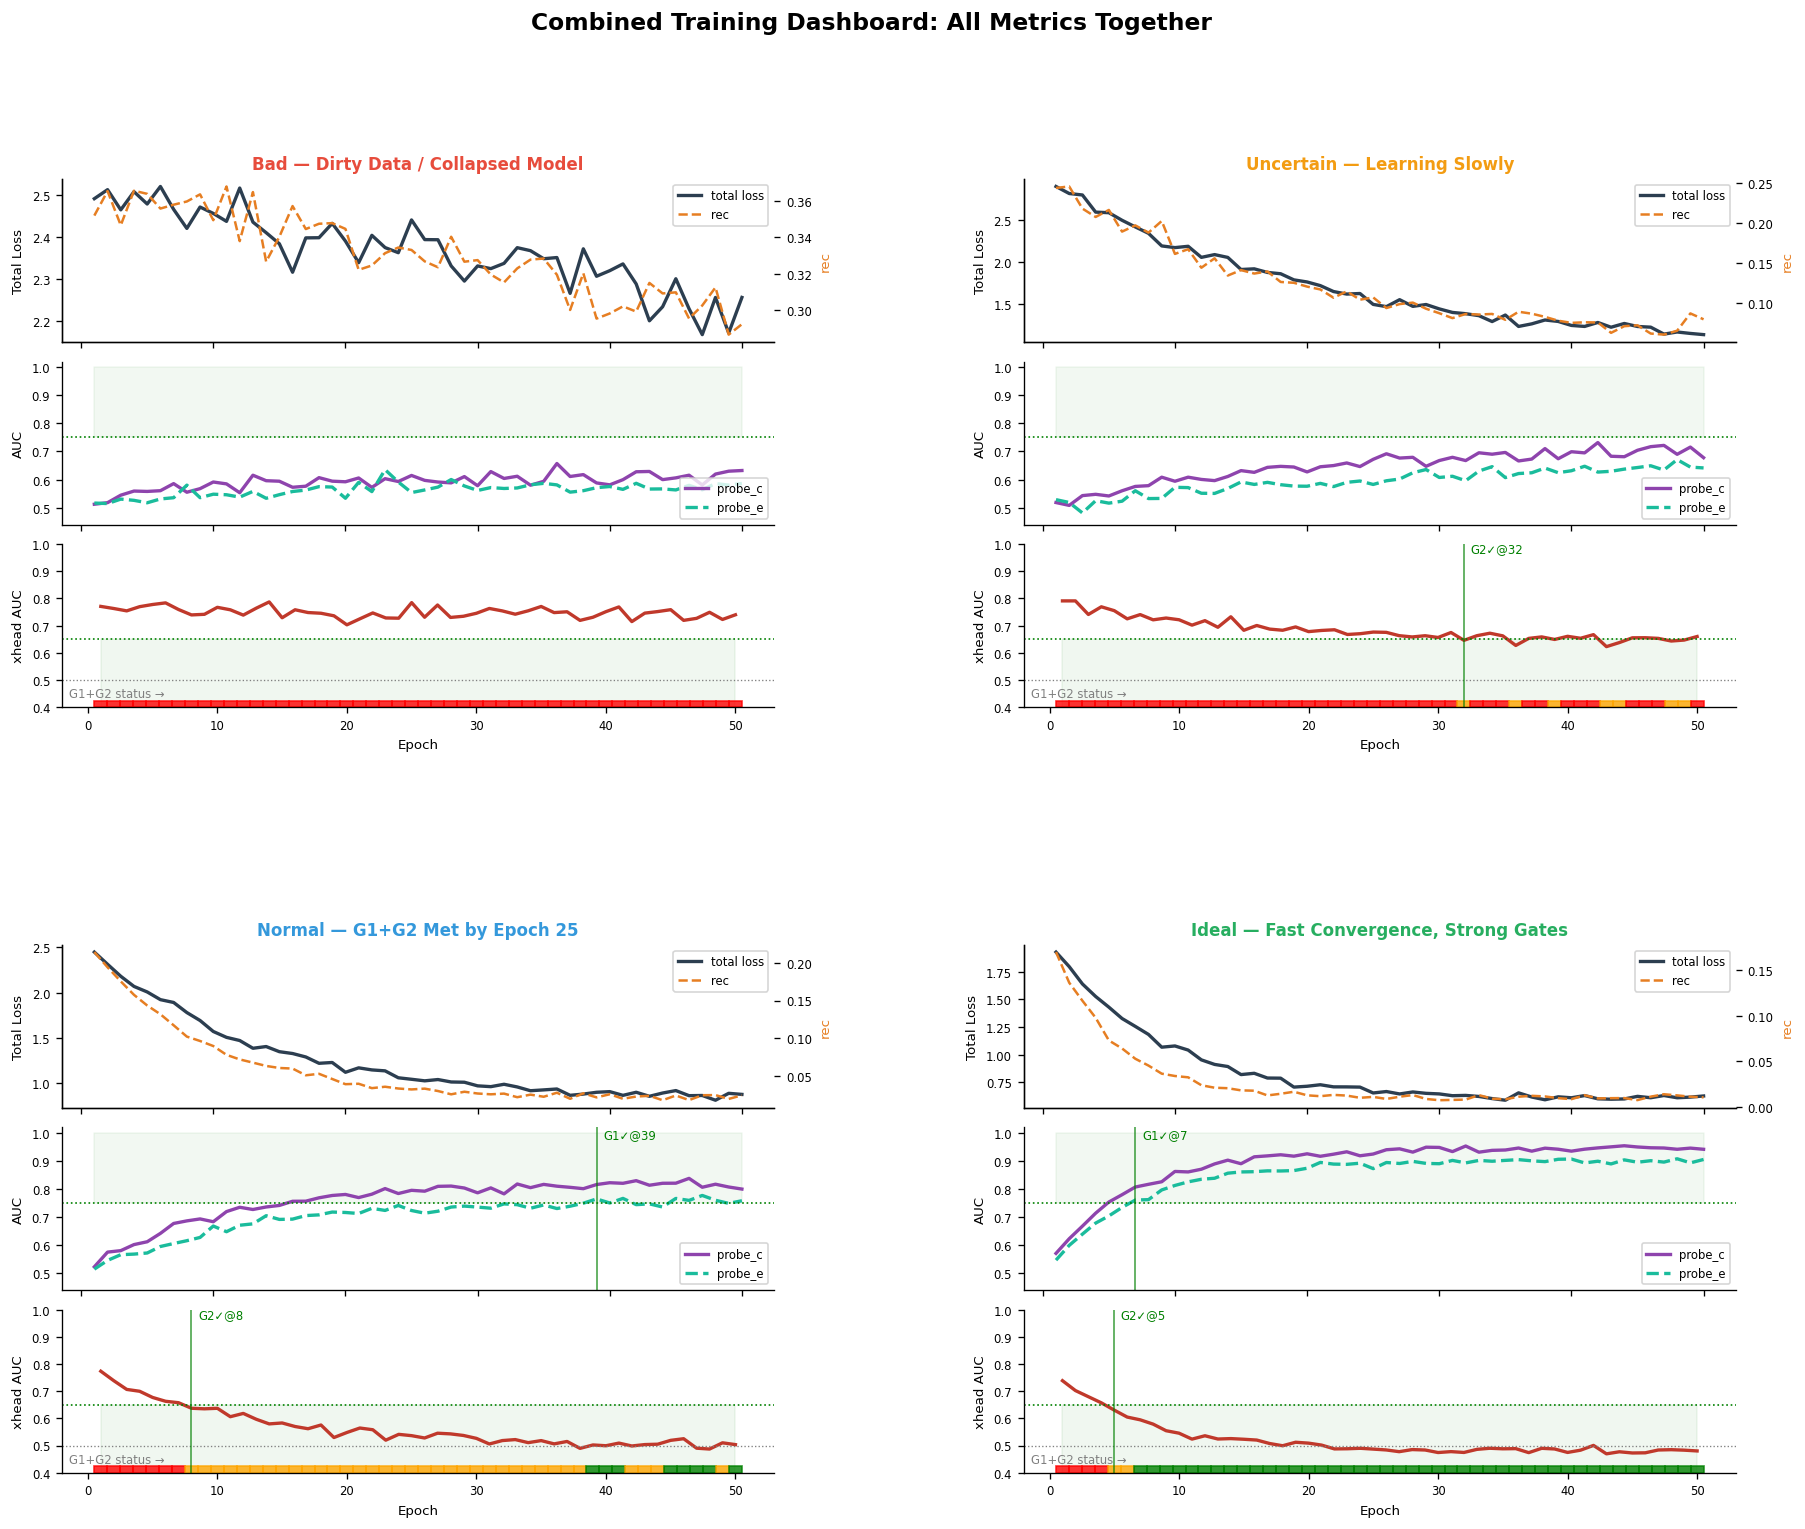

In [9]:
np.random.seed(55)

def simulate_run(scenario, n_epochs=50):
    """Simulate a realistic training trajectory for a given scenario."""
    e = np.arange(1, n_epochs+1)
    noise = lambda scale: scale * np.random.randn(n_epochs)
    
    if scenario == 'bad':  # dirty data, model cannot learn
        rec    = 0.22 * np.exp(-0.008*e) + 0.15 + noise(0.01)
        probe_c = 0.5 + 0.03 * np.log(e+1) + noise(0.015)
        probe_e = 0.5 + 0.02 * np.log(e+1) + noise(0.015)
        xhead  = 0.78 - 0.01 * np.log(e+1) + noise(0.015)
        total  = 2.5 - 0.005*e + noise(0.05)
    
    elif scenario == 'uncertain':  # partially working, rec ok, probes slow
        rec    = 0.20 * np.exp(-0.06*e) + 0.06 + noise(0.008)
        probe_c = np.clip(0.5 + 0.22*(1-np.exp(-e/18)) + noise(0.015), 0.45, 1)
        probe_e = np.clip(0.5 + 0.15*(1-np.exp(-e/22)) + noise(0.015), 0.45, 1)
        xhead  = np.clip(0.78 - 0.15*(1-np.exp(-e/20)) + noise(0.012), 0.4, 1)
        total  = 2.0 * np.exp(-0.05*e) + 1.0 + noise(0.04)
    
    elif scenario == 'normal':  # good training, G1+G2 met by ~epoch 25
        rec    = np.clip(0.22 * np.exp(-0.12*e) + 0.022 + noise(0.003), 0, 0.5)
        probe_c = np.clip(0.5 + 0.32*(1-np.exp(-e/10)) + noise(0.010), 0, 1)
        probe_e = np.clip(0.5 + 0.26*(1-np.exp(-e/12)) + noise(0.010), 0, 1)
        xhead  = np.clip(0.78 - 0.28*(1-np.exp(-e/12)) + noise(0.010), 0.4, 1)
        total  = 1.8 * np.exp(-0.08*e) + 0.8 + noise(0.03)
    
    else:  # ideal — fast convergence, both gates met early
        rec    = np.clip(0.20 * np.exp(-0.22*e) + 0.010 + noise(0.002), 0, 0.5)
        probe_c = np.clip(0.5 + 0.44*(1-np.exp(-e/6)) + noise(0.007), 0, 1)
        probe_e = np.clip(0.5 + 0.40*(1-np.exp(-e/7)) + noise(0.007), 0, 1)
        xhead  = np.clip(0.78 - 0.30*(1-np.exp(-e/7)) + noise(0.007), 0.4, 1)
        total  = 1.5 * np.exp(-0.12*e) + 0.6 + noise(0.02)
    
    total  = np.clip(total, 0.1, 5)
    rec    = np.clip(rec,   0.001, 0.4)
    probe_c = np.clip(probe_c, 0.45, 1.0)
    probe_e = np.clip(probe_e, 0.45, 1.0)
    xhead  = np.clip(xhead,  0.4, 1.0)
    
    g1 = (probe_c > 0.75) & (probe_e > 0.75)
    g2 = xhead < 0.65
    
    return dict(epochs=e, total=total, rec=rec, probe_c=probe_c,
                probe_e=probe_e, xhead=xhead, g1=g1, g2=g2)


fig = plt.figure(figsize=(18, 14))
outer = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

scenario_configs = [
    ('bad',      'Bad — Dirty Data / Collapsed Model',    COLORS['bad']),
    ('uncertain','Uncertain — Learning Slowly',           COLORS['uncertain']),
    ('normal',   'Normal — G1+G2 Met by Epoch 25',        COLORS['normal']),
    ('ideal',    'Ideal — Fast Convergence, Strong Gates', COLORS['ideal']),
]

fig.suptitle('Combined Training Dashboard: All Metrics Together', fontsize=14, fontweight='bold')

for idx, (sc, sc_title, sc_color) in enumerate(scenario_configs):
    row, col = divmod(idx, 2)
    inner = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=outer[row, col], hspace=0.12)
    
    run = simulate_run(sc)
    e = run['epochs']
    
    # Row 1: total loss + rec
    ax1 = fig.add_subplot(inner[0])
    ax1_r = ax1.twinx()
    ax1.plot(e, run['total'], color='#2c3e50', lw=2, label='total loss')
    ax1_r.plot(e, run['rec'], color='#e67e22', lw=1.5, linestyle='--', label='rec')
    ax1.set_ylabel('Total Loss', fontsize=8)
    ax1_r.set_ylabel('rec', fontsize=8, color='#e67e22')
    ax1.set_title(sc_title, color=sc_color, fontweight='bold', fontsize=10)
    ax1.tick_params(labelbottom=False, labelsize=7)
    ax1_r.tick_params(labelsize=7)
    lines1 = ax1.get_lines() + ax1_r.get_lines()
    ax1.legend(lines1, [l.get_label() for l in lines1], loc='upper right', fontsize=7)
    
    # Row 2: probes
    ax2 = fig.add_subplot(inner[1])
    ax2.plot(e, run['probe_c'], color='#8e44ad', lw=2, label='probe_c')
    ax2.plot(e, run['probe_e'], color='#1abc9c', lw=2, linestyle='--', label='probe_e')
    ax2.axhline(0.75, color='green', linestyle=':', lw=1)
    ax2.fill_between(e, 0.75, 1.0, alpha=0.05, color='green')
    ax2.set_ylabel('AUC', fontsize=8)
    ax2.set_ylim(0.44, 1.02)
    ax2.tick_params(labelbottom=False, labelsize=7)
    ax2.legend(fontsize=7, loc='lower right')
    
    # Mark G1 gate epoch
    g1_epochs = np.where(run['g1'])[0]
    if len(g1_epochs) > 0:
        g1_ep = g1_epochs[0] + 1
        ax2.axvline(g1_ep, color='green', alpha=0.7, lw=1)
        ax2.text(g1_ep+0.5, 0.98, f'G1✓@{g1_ep}', color='green', fontsize=7)
    
    # Row 3: xhead + gate ticks
    ax3 = fig.add_subplot(inner[2])
    ax3.plot(e, run['xhead'], color='#c0392b', lw=2, label='xhead')
    ax3.axhline(0.65, color='green', linestyle=':', lw=1)
    ax3.axhline(0.50, color='gray', linestyle=':', lw=0.8)
    ax3.fill_between(e, 0.4, 0.65, alpha=0.06, color='green')
    ax3.set_ylabel('xhead AUC', fontsize=8)
    ax3.set_xlabel('Epoch', fontsize=8)
    ax3.set_ylim(0.4, 1.0)
    ax3.tick_params(labelsize=7)
    
    g2_epochs = np.where(run['g2'])[0]
    if len(g2_epochs) > 0:
        g2_ep = g2_epochs[0] + 1
        ax3.axvline(g2_ep, color='green', alpha=0.7, lw=1)
        ax3.text(g2_ep+0.5, 0.97, f'G2✓@{g2_ep}', color='green', fontsize=7)
    
    # G1/G2 gate bar at bottom of ax3
    gate_colors = [('green' if (g1 and g2) else 'orange' if (g1 or g2) else 'red')
                   for g1, g2 in zip(run['g1'], run['g2'])]
    for ep, gc in zip(e, gate_colors):
        ax3.axvspan(ep-0.5, ep+0.5, ymin=0, ymax=0.04, color=gc, alpha=0.8)
    ax3.text(0.01, 0.06, 'G1+G2 status →', transform=ax3.transAxes, fontsize=7, color='gray')

plt.savefig('../results/combined_scenarios.png', bbox_inches='tight')
plt.show()

---
# Part 4: Gate Logic Decision Tree

At the end of each epoch:
- **G1** = `probe_c > 0.75` AND `probe_e > 0.75`
- **G2** = `xhead < 0.65`

What does each combination mean for **experiment progression**?

/tmp/ipykernel_2863803/2729192331.py:9: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  rect = plt.Rectangle((x-w/2, y-h/2), w, h, color=color, zorder=3, linewidth=1.5,


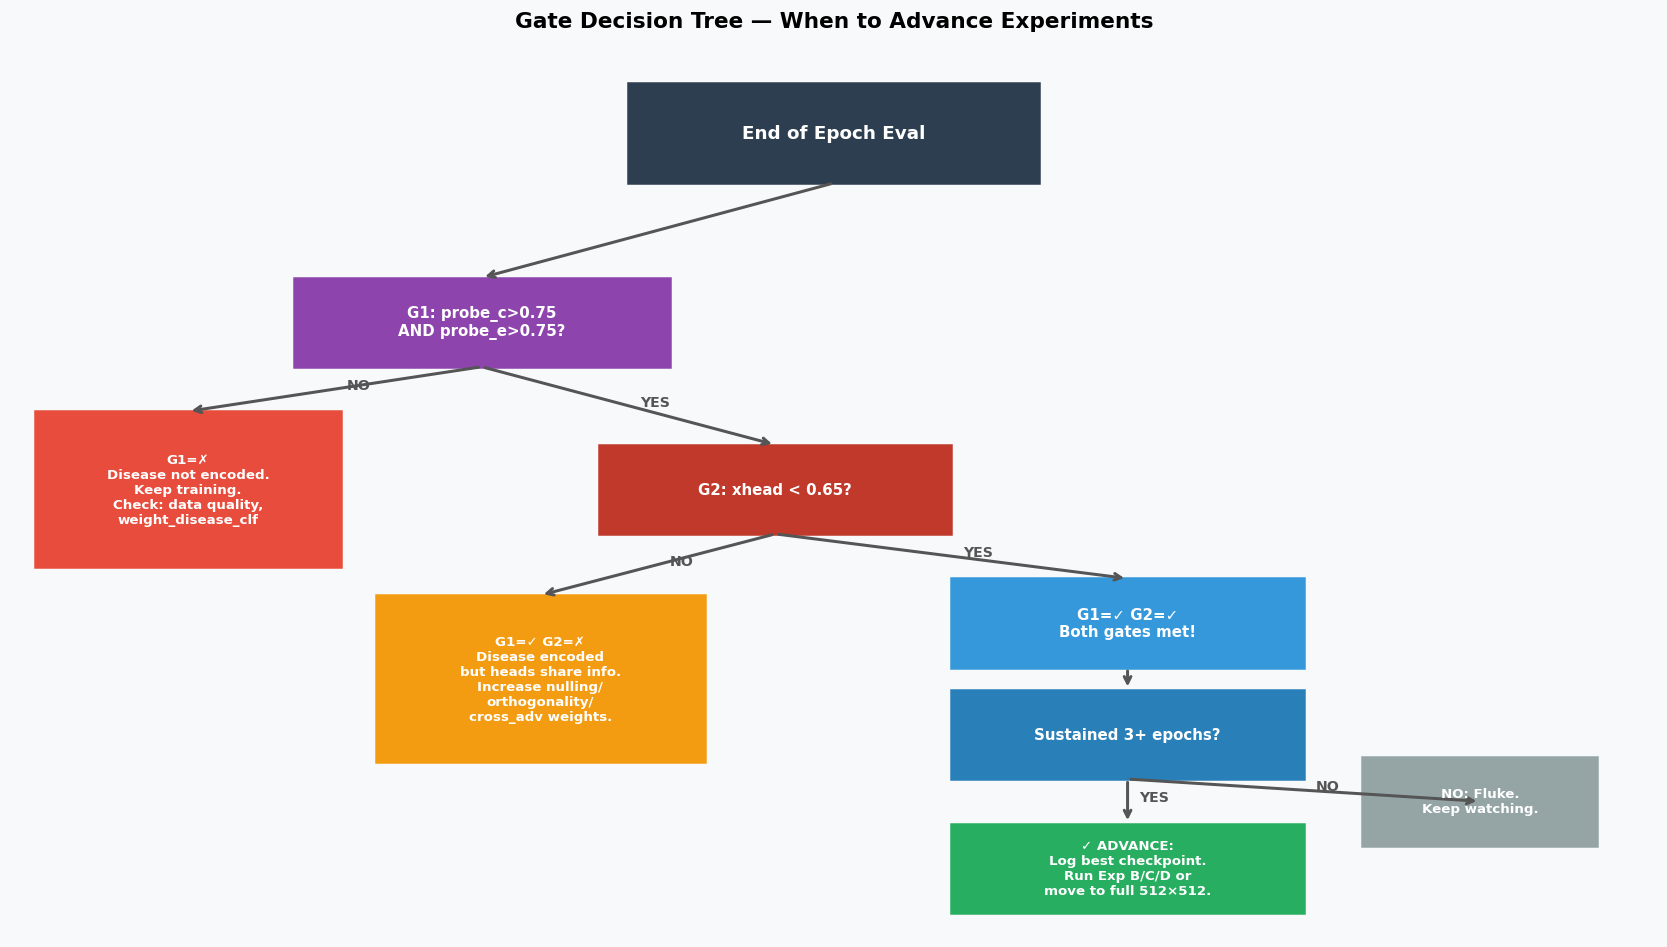

In [10]:
fig, ax = plt.subplots(figsize=(14, 8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis('off')
ax.set_facecolor('#f8f9fa')
fig.patch.set_facecolor('#f8f9fa')

def box(ax, x, y, w, h, text, color, fontsize=10, text_color='white'):
    rect = plt.Rectangle((x-w/2, y-h/2), w, h, color=color, zorder=3, linewidth=1.5,
                          edgecolor='white')
    ax.add_patch(rect)
    ax.text(x, y, text, ha='center', va='center', fontsize=fontsize,
            color=text_color, fontweight='bold', zorder=4,
            wrap=True, multialignment='center')

def arrow(ax, x1, y1, x2, y2, label='', color='#555'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
    if label:
        mx, my = (x1+x2)/2, (y1+y2)/2
        ax.text(mx+0.1, my, label, fontsize=8.5, color=color, fontweight='bold')

# Root
box(ax, 7, 7.2, 3.5, 0.9, 'End of Epoch Eval', '#2c3e50', fontsize=11)

# G1 branch
box(ax, 4, 5.5, 3.2, 0.8, 'G1: probe_c>0.75\nAND probe_e>0.75?', '#8e44ad', fontsize=9)
arrow(ax, 7, 6.75, 4, 5.9)

# G1=No
box(ax, 1.5, 4.0, 2.6, 1.4,
    'G1=✗\nDisease not encoded.\nKeep training.\nCheck: data quality,\nweight_disease_clf', 
    COLORS['bad'], fontsize=8)
arrow(ax, 4, 5.1, 1.5, 4.7, 'NO')

# G1=Yes → G2 branch
box(ax, 6.5, 4.0, 3.0, 0.8, 'G2: xhead < 0.65?', '#c0392b', fontsize=9)
arrow(ax, 4, 5.1, 6.5, 4.4, 'YES')

# G2=No
box(ax, 4.5, 2.3, 2.8, 1.5,
    'G1=✓ G2=✗\nDisease encoded\nbut heads share info.\nIncrease nulling/\northogonality/\ncross_adv weights.',
    COLORS['uncertain'], fontsize=8)
arrow(ax, 6.5, 3.6, 4.5, 3.05, 'NO')

# G2=Yes
box(ax, 9.5, 2.8, 3.0, 0.8, 'G1=✓ G2=✓\nBoth gates met!', COLORS['normal'], fontsize=9)
arrow(ax, 6.5, 3.6, 9.5, 3.2, 'YES')

# Sustained check
box(ax, 9.5, 1.8, 3.0, 0.8, 'Sustained 3+ epochs?', '#2980b9', fontsize=9)
arrow(ax, 9.5, 2.4, 9.5, 2.2)

# No: fluke
box(ax, 12.5, 1.2, 2.0, 0.8,
    'NO: Fluke.\nKeep watching.', '#95a5a6', fontsize=8)
arrow(ax, 9.5, 1.4, 12.5, 1.2, 'NO')

# Yes: advance
box(ax, 9.5, 0.6, 3.0, 0.8,
    '✓ ADVANCE:\nLog best checkpoint.\nRun Exp B/C/D or\nmove to full 512×512.',
    COLORS['ideal'], fontsize=8)
arrow(ax, 9.5, 1.4, 9.5, 1.0, 'YES')

ax.set_title('Gate Decision Tree — When to Advance Experiments', fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig('../results/gate_decision_tree.png', bbox_inches='tight')
plt.show()

---
# Part 5: What Should the Probes Be?

## Why we use linear probes (not the discriminator loss)

The **disease_clf loss** (R11) is an adversarial game — the discriminator vs the encoder. It's noisy and doesn't directly tell you AUC. The **linear probe** is an **independent diagnostic**: frozen latents → fit logistic regression → report AUC. It's the ground truth of "how much disease info is in this head."

## Breakdown by class balance

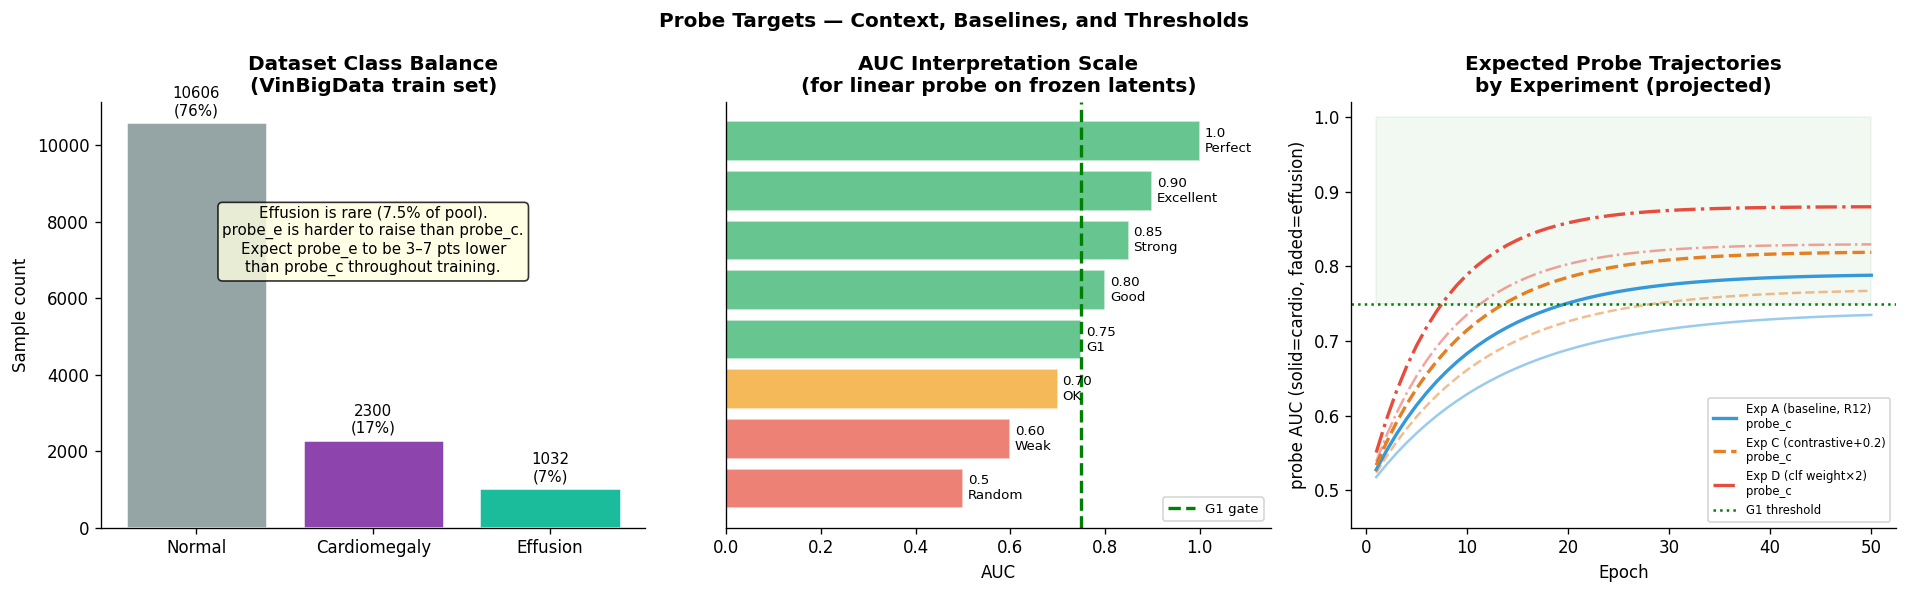

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Probe Targets — Context, Baselines, and Thresholds', fontsize=12, fontweight='bold')

# Left: class balance and AUC interpretation
ax = axes[0]
classes = ['Normal', 'Cardiomegaly', 'Effusion']
counts  = [10606, 2300, 1032]
total   = sum(counts)
ratios  = [c/total for c in counts]
colors_bar = ['#95a5a6', '#8e44ad', '#1abc9c']
bars = ax.bar(classes, counts, color=colors_bar, edgecolor='white', linewidth=1.5)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{count}\n({count/total*100:.0f}%)', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Sample count')
ax.set_title('Dataset Class Balance\n(VinBigData train set)', fontweight='bold')
ax.text(0.5, 0.6,
    'Effusion is rare (7.5% of pool).\n'
    'probe_e is harder to raise than probe_c.\n'
    'Expect probe_e to be 3–7 pts lower\nthan probe_c throughout training.',
    transform=ax.transAxes, ha='center', fontsize=9,
    bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# Middle: AUC thresholds explained
ax = axes[1]
thresholds = [0.5, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 1.0]
labels_t   = ['0.5\nRandom', '0.60\nWeak', '0.70\nOK', '0.75\nG1', '0.80\nGood', '0.85\nStrong', '0.90\nExcellent', '1.0\nPerfect']
gradient_colors = ['#e74c3c', '#e74c3c', '#f39c12', '#27ae60', '#27ae60', '#27ae60', '#27ae60', '#27ae60']
ax.barh(range(len(thresholds)), thresholds, color=gradient_colors, edgecolor='white', alpha=0.7)
for i, (t, l) in enumerate(zip(thresholds, labels_t)):
    ax.text(t + 0.01, i, l, va='center', fontsize=8)
ax.axvline(0.75, color='green', linestyle='--', lw=2, label='G1 gate')
ax.set_xlim(0, 1.15)
ax.set_yticks([])
ax.set_xlabel('AUC')
ax.set_title('AUC Interpretation Scale\n(for linear probe on frozen latents)', fontweight='bold')
ax.legend(fontsize=8)

# Right: expected trajectory by experiment
ax = axes[2]
e = np.arange(1, 51)
np.random.seed(42)
exp_scenarios = {
    'Exp A (baseline, R12)':    (0.5 + 0.29*(1-np.exp(-e/10)), 0.5 + 0.24*(1-np.exp(-e/13))),
    'Exp C (contrastive+0.2)':  (0.5 + 0.32*(1-np.exp(-e/9)),  0.5 + 0.27*(1-np.exp(-e/11))),
    'Exp D (clf weight×2)':     (0.5 + 0.38*(1-np.exp(-e/7)),  0.5 + 0.33*(1-np.exp(-e/8))),
}
line_styles = ['-', '--', '-.']
exp_colors  = ['#3498db', '#e67e22', '#e74c3c']
for (name, (pc, pe)), ls, ec in zip(exp_scenarios.items(), line_styles, exp_colors):
    ax.plot(e, np.clip(pc, 0, 1), color=ec, lw=2, linestyle=ls, label=f'{name}\nprobe_c')
    ax.plot(e, np.clip(pe, 0, 1), color=ec, lw=1.5, linestyle=ls, alpha=0.5)

ax.axhline(0.75, color='green', linestyle=':', lw=1.5, label='G1 threshold')
ax.fill_between(e, 0.75, 1.0, alpha=0.05, color='green')
ax.set_xlabel('Epoch')
ax.set_ylabel('probe AUC (solid=cardio, faded=effusion)')
ax.set_title('Expected Probe Trajectories\nby Experiment (projected)', fontweight='bold')
ax.set_ylim(0.45, 1.02)
ax.legend(fontsize=7, loc='lower right')

plt.tight_layout()
plt.savefig('../results/probe_targets.png', bbox_inches='tight')
plt.show()

---
# Part 6: Distribution View — What Latents Look Like When It Works vs When It Doesn't

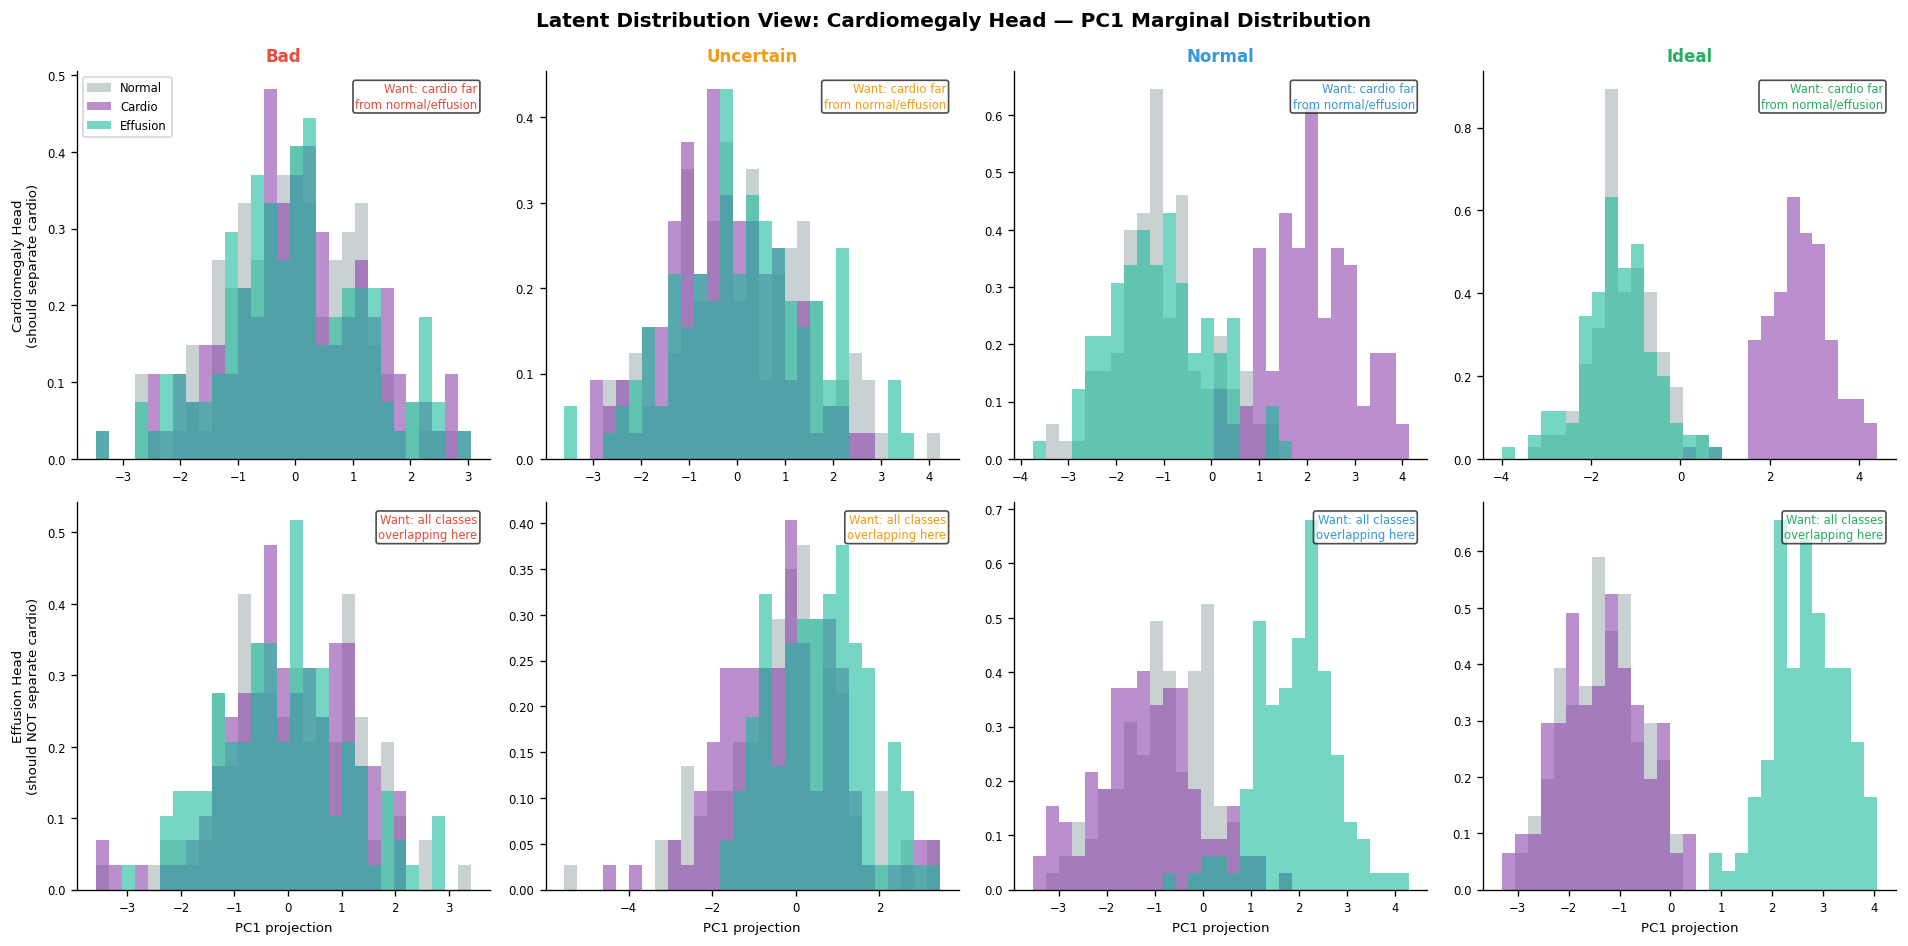

In [12]:
np.random.seed(77)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Latent Distribution View: Cardiomegaly Head — PC1 Marginal Distribution',
             fontsize=12, fontweight='bold')

row_labels = ['Cardiomegaly Head\n(should separate cardio)', 'Effusion Head\n(should NOT separate cardio)']
sc_names   = ['Bad', 'Uncertain', 'Normal', 'Ideal']

for col, sc in enumerate(['bad', 'uncertain', 'normal', 'ideal']):
    cardio_h, eff_h = make_latents(sc)
    
    # PCA project onto 1D
    for row, (head, head_name) in enumerate([(cardio_h, 'Cardiomegaly Head'), (eff_h, 'Effusion Head')]):
        ax = axes[row, col]
        all_data = np.vstack([head['normal'], head['cardio'], head['effusion']])
        pca1d = PCA(n_components=1).fit_transform(all_data)
        pca1d = pca1d.ravel()
        
        n_pca   = pca1d[:N]
        c_pca   = pca1d[N:2*N]
        e_pca   = pca1d[2*N:]
        
        bins = np.linspace(pca1d.min(), pca1d.max(), 30)
        ax.hist(n_pca, bins=bins, alpha=0.5, color='#95a5a6', label='Normal', density=True)
        ax.hist(c_pca, bins=bins, alpha=0.6, color='#8e44ad', label='Cardio',  density=True)
        ax.hist(e_pca, bins=bins, alpha=0.6, color='#1abc9c', label='Effusion',density=True)
        
        if row == 0:
            ax.set_title(sc_names[col], color=list(COLORS.values())[col],
                         fontweight='bold', fontsize=10)
        if col == 0:
            ax.set_ylabel(row_labels[row], fontsize=8)
        if row == 1:
            ax.set_xlabel('PC1 projection', fontsize=8)
        ax.tick_params(labelsize=7)
        if row == 0 and col == 0:
            ax.legend(fontsize=7)
        
        # Annotation
        if row == 0:
            note = 'Want: cardio far\nfrom normal/effusion'
            color_note = list(COLORS.values())[col]
        else:
            note = 'Want: all classes\noverlapping here'
            color_note = list(COLORS.values())[col]
        ax.text(0.97, 0.97, note, transform=ax.transAxes, fontsize=7,
                ha='right', va='top', color=color_note,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.savefig('../results/latent_distributions.png', bbox_inches='tight')
plt.show()

---
# Quick Reference: Epoch-by-Epoch Checklist

```
Epoch  1–5:   rec dropping fast (0.20→0.05). loss high (KL warmup). probes ~0.50–0.55 (normal). xhead ~0.75 (normal).
Epoch  5–15:  rec <0.05. probes climbing (0.55→0.70). xhead dropping (0.75→0.67). 
               ⚠ If probes flat at 0.50 → data quality issue or weight_disease_clf too low.
Epoch 15–25:  probes should cross 0.75 (G1). xhead should cross 0.65 (G2).
               ⚠ If G1 not met by epoch 30 → adjust Exp D (higher clf weight) or check collate_fn.
               ⚠ If G2 not met by epoch 30 → increase nulling/orthogonality, enable contrastive (Exp C).
Epoch 25–50:  Both gates met and sustained. PCA shows clear cluster separation per head.
               ideal: probe_c>0.85, probe_e>0.80, xhead<0.60.
```

**Summary table — one-liner interpretation:**

| Pattern | Diagnosis | Action |
|---------|-----------|--------|
| `rec` high (>0.10) sustained | Bad reconstruction | Check image loading, windowing, flip |
| `probe_c/e` flat at 0.50 | Disease info absent | Dirty data, or `weight_disease_clf` too low |
| `probe_c` high, `probe_e` low | Effusion underfit | Class imbalance (1032 vs 2300), needs more epochs |
| `xhead` stuck >0.70 | Severe leakage | Raise nulling/ortho, add contrastive (Exp C) |
| `G1=✓ G2=✗` | Good encoding, poor disentanglement | Experiment C (contrastive) or higher nulling |
| `G1=✗ G2=✓` | Disentangled but weak signal | Experiment D (higher clf weight) |
| `G1=✓ G2=✓` sustained | ✅ Ready to advance | Save best checkpoint, move to full 512×512 |